<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/OT-day5/OT_Day5_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ONNX·TensorRT Day 5 — 탐지 모델 TensorRT · 종합 프로젝트: 위험구역 침입 감지

**온디바이스 AI · ONNX·TensorRT 5/5 · 11/10(화)** · Google Colab (**T4 GPU 런타임 필수**) · TensorRT 10.16.1.11 · YOLOv8n · OpenCV

어제 만든 `build_engine` · `trt_runner` 를 **`TRTInfer` 클래스**로 묶어 **YOLOv8n** 에 그대로 씁니다. 그리고 VB Day 5 의 **위험구역 침입 감지기**에서 **추론 한 곳만** TensorRT 로 바꿔, 녹화 영상으로 결과 영상 · 이벤트 기록 · 최종 성능표를 만듭니다.

> 5일의 마지막 계단: **내보내기 → 열어보기 → 실행하기 → 빠르게 하기** → 그리고 **실제 파이프라인에 넣기**.

오늘의 목표

1. 엔진 빌드 · 실행 함수를 `TRTInfer` 클래스 (`__init__` 에서 준비, `__call__` 에서 실행) 로 묶는다.
2. YOLOv8n 을 FP16 엔진으로 바꾸고, VB 의 전처리 (letterbox) · 후처리 (decode · NMS) 를 그대로 연결한다.
3. Penn-Fudan 정답 박스로 ORT · TensorRT FP32 · FP16 의 **AP** 를 비교해 FP16 의 정확도를 확인한다.
4. 한 프레임을 **전처리 · 추론 · 후처리 · 그리기**로 나눠 재고, 추론이 빨라진 뒤의 병목을 찾는다.
5. 침입 감지 코드에서 추론기만 교체해 결과 영상 · 프레임 로그 · 이벤트 CSV 를 만들고, ORT CPU 버전과 FPS 를 비교한다.
6. 결과를 3분 안에 발표하고, 5일 내용을 종합 퀴즈로 정리한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 4 복습 퀴즈 · 함수 → 클래스 `TRTInfer` |
| 2 | 10:00–10:50 | YOLOv8n 엔진 만들기 · VB 전처리 · 후처리 연결 |
| 3 | 11:00–11:50 | 정확도 확인 — ORT vs TRT FP32 vs FP16 AP |
| 4 | 13:00–13:50 | 시간 나눠 재기 — 전처리 · 추론 · 후처리 · 그리기 |
| 5 | 14:00–14:50 | 미니 프로젝트 ① 이식 — 추론기만 교체 (과제 1 · 2) |
| 6 | 15:00–15:50 | 미니 프로젝트 ② 결과 만들기 — 영상 · 이벤트 · 성능표 (과제 3 · 4 · 채점) |
| 7 | 16:00–16:50 | 팀 발표 — 3분 (과제 5) |
| 8 | 17:00–17:50 | 5일 종합 퀴즈 30문항 · 제출 · 다음 과목 연결 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → **T4 GPU*** 필수. 설치 셀 → 환경 셀 → 데이터 셀 순서로.
2. `____` 빈칸 → 실행 → **확인 셀** `✅`. 막히면 **🔒 정답 보기**.
3. **엔진 빌드는 오래 걸립니다** — YOLOv8n 은 FP16 · FP32 각각 수 분. 빌드 셀을 누르고 설명을 읽으며 기다리세요. 이미 만든 엔진은 다시 만들지 않도록 해 두었습니다.
4. 시간 · FPS · AP 는 Colab 장비 · 버전마다 조금씩 다릅니다. 확인 · 채점 셀은 값이 아니라 **방법과 일관성**을 검사합니다.
5. 오늘 끝에 **제출 파일** (`trt_이름.zip`) 을 만듭니다 — 노트북도 함께 제출.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/OT_Day5.pdf](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/OT_Day5.pdf) |

**오늘의 데이터** — VB 에서 쓴 그대로: **YOLOv8n** (`yolov8n.onnx`, 입력 640, opset 17 — VB Day 5 에서 export 한 것과 같은 방식), **Penn-Fudan** 보행자 170장 (정답 박스), **보행자 영상** `people.mp4` (768×576, 10 FPS, 795 프레임).

In [ ]:
# ▶ 설치 셀 — TensorRT · GPU 판 ONNX Runtime (Day 4 와 같음). 처음 한 번, 2~3분
%pip uninstall -y -q onnxruntime
%pip install -q onnx onnxruntime-gpu "tensorrt-cu12==10.16.1.11"

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, re, glob, time, json, csv, base64, inspect, subprocess, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torchvision
import onnx
import onnxruntime as ort
import tensorrt as trt
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/OT-day5"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
try:
    ort.preload_dlls()
except Exception:
    pass
GPU_OK = torch.cuda.is_available()

def fetch(name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

def show(imgs, titles=None, cols=2, size=4.5):
    imgs = list(imgs); rows = (len(imgs) + cols - 1) // cols
    plt.figure(figsize=(size * min(cols, len(imgs)), size * 0.75 * rows))
    for i, im in enumerate(imgs):
        plt.subplot(rows, min(cols, len(imgs)), i + 1); plt.imshow(im[..., ::-1]); plt.axis("off")
        if titles is not None: plt.title(titles[i], fontsize=10)
    plt.tight_layout(); plt.show()

# ── Day 3 · Day 4 에서 만든 함수 ─────────────────────────────────────
def bench_fn(fn, n=100, warm=10, batch=1):
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": t.mean(), "p50": np.percentile(t, 50), "p95": np.percentile(t, 95), "fps": 1000 / t.mean() * batch}

LOGGER = trt.Logger(trt.Logger.WARNING)
RUNTIME = trt.Runtime(LOGGER)

def build_engine(onnx_path, engine_path, fp16=False):
    builder = trt.Builder(LOGGER)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, LOGGER)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    if fp16:
        config.set_flag(trt.BuilderFlag.FP16)
    blob = builder.build_serialized_network(network, config)
    if blob is None:
        raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
    with open(engine_path, "wb") as f:
        f.write(blob)
    return engine_path

def build_once(onnx_path, engine_path, fp16=False):
    """엔진이 이미 있으면 다시 만들지 않는다 (빌드는 수 분)"""
    if not os.path.exists(engine_path):
        t0 = time.time(); build_engine(onnx_path, engine_path, fp16)
        print(f"빌드 {engine_path} — {time.time() - t0:.0f} 초")
    return engine_path

def make_mnv3s():                            # Day 3 · 4 와 같은 모델 (구조만)
    torch.manual_seed(0)
    m = torchvision.models.mobilenet_v3_small(weights=None)
    with torch.no_grad():
        for b in m.modules():
            if isinstance(b, nn.BatchNorm2d):
                b.running_mean.uniform_(-0.1, 0.1); b.running_var.uniform_(0.5, 1.5)
    return m.eval()

# ── VB Day 4 에서 만든 함수 (iou_nms_map.py) ─────────────────────────
def iou(box, boxes):
    box = np.asarray(box, float); boxes = np.asarray(boxes, float).reshape(-1, 4)
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / (area(box) + area(boxes) - inter)

def iou_matrix(A, B):
    A = np.asarray(A, float).reshape(-1, 4); B = np.asarray(B, float).reshape(-1, 4)
    x1 = np.maximum(A[:, None, 0], B[None, :, 0]); y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2]); y2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aA = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1]); aB = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return inter / (aA[:, None] + aB[None, :] - inter)

def nms(boxes, scores, iou_thr=0.5):
    boxes = np.asarray(boxes, float); scores = np.asarray(scores, float)
    order = np.argsort(-scores); keep = []
    while order.size > 0:
        i = order[0]; keep.append(i); rest = order[1:]
        order = rest[iou(boxes[i], boxes[rest]) <= iou_thr]
    return np.array(keep, dtype=int)

def letterbox(img, size=640, color=114):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8)
    out[top:top + nh, left:left + nw] = resized
    return out, r, (left, top)

def decode_yolo(out, conf_thr=0.25, iou_thr=0.7, cls=0):
    p = np.asarray(out)[0].T                              # (8400, 84)
    boxes_c, cls_scores = p[:, :4], p[:, 4:]
    best, conf = cls_scores.argmax(1), cls_scores.max(1)
    m = (conf > conf_thr) & (best == cls)
    cx, cy, w, h = boxes_c[m].T
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)
    keep = nms(boxes, conf[m], iou_thr)
    return boxes[keep], conf[m][keep]

def ap_from_pr(rec, prec):
    mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[0.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def match_detections(dets, gts, iou_thr=0.5):
    recs = []
    for i, d in enumerate(dets):
        for row in np.asarray(d, float).reshape(-1, 5):
            recs.append((row[4], i, row[:4]))
    recs.sort(key=lambda t: -t[0])
    used = [np.zeros(len(g), bool) for g in gts]
    scores, tp = [], []
    for s, i, b in recs:
        ok = 0
        if len(gts[i]):
            o = iou(b, gts[i]); j = int(o.argmax())
            if o[j] >= iou_thr and not used[i][j]:
                used[i][j] = True; ok = 1
        scores.append(s); tp.append(ok)
    return np.array(scores), np.array(tp), sum(len(g) for g in gts)

def evaluate_ap(dets, gts, iou_thr=0.5):
    scores, tp, n_gt = match_detections(dets, gts, iou_thr)
    ctp = np.cumsum(tp); precision, recall = ctp / np.arange(1, len(tp) + 1), ctp / n_gt
    return ap_from_pr(recall, precision)

def map_50_95(dets, gts):
    return float(np.mean([evaluate_ap(dets, gts, t) for t in np.arange(0.5, 0.96, 0.05)]))

# ── VB Day 5 침입 감지 함수 ──────────────────────────────────────────
GRASS = np.array([(0, 270), (180, 300), (380, 350), (520, 470), (560, 575), (0, 575)], np.int32)   # 위험구역 (잔디)

def in_zone(pt, poly=GRASS):
    return cv2.pointPolygonTest(poly, (float(pt[0]), float(pt[1])), False) >= 0

def foot_points(boxes):
    boxes = np.asarray(boxes, float).reshape(-1, 4)
    return np.stack([(boxes[:, 0] + boxes[:, 2]) / 2, boxes[:, 3]], 1)

def draw_result(frame, boxes, inside, alarm, poly=GRASS, fps=None):
    """구역 · 박스 · 발 위치 · 경보 · FPS 를 그린 새 프레임"""
    ov = frame.copy(); cv2.fillPoly(ov, [poly], (0, 0, 255))
    out = cv2.addWeighted(ov, 0.45 if alarm else 0.15, frame, 0.55 if alarm else 0.85, 0)
    cv2.polylines(out, [poly], True, (0, 0, 255), 2)
    for b, f_, ins in zip(np.asarray(boxes).astype(int), foot_points(boxes).astype(int), inside):
        col = (0, 0, 255) if ins else (0, 200, 0)
        cv2.rectangle(out, tuple(b[:2]), tuple(b[2:]), col, 2); cv2.circle(out, tuple(f_), 4, col, -1)
    cv2.putText(out, f"people {len(boxes)}  in zone {int(np.sum(inside))}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    if fps is not None:
        cv2.putText(out, f"{fps:.1f} FPS", (out.shape[1] - 150, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    if alarm:
        cv2.putText(out, "INTRUSION ALARM", (10, 62), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 255), 3)
    return out

print("PyTorch", torch.__version__, "| ONNX Runtime", ort.__version__, "| TensorRT", trt.__version__, "| OpenCV", cv2.__version__)
print("GPU:", torch.cuda.get_device_name(0) if GPU_OK else "없음 ⚠️ — 런타임 유형을 T4 GPU 로 바꾸고 설치 셀부터 다시")

In [ ]:
# ▶ 데이터 셀 — Penn-Fudan (약 50 MB) · 보행자 영상 · YOLOv8n ONNX
PF = "PennFudanPed"
if not os.path.exists(f"{PF}/PNGImages"):
    r = subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/swallan/PennFudanPed.git", PF])
    if r.returncode != 0:
        import zipfile
        urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "PennFudanPed.zip")
        zipfile.ZipFile("PennFudanPed.zip").extractall(".")
VIDEO = fetch("people.mp4")
YOLO_ONNX = fetch("yolov8n.onnx")

def parse_annotation(path):
    pairs = re.findall(r"\((\d+), (\d+)\) - \((\d+), (\d+)\)", open(path, encoding="latin-1").read())
    return np.array(pairs, dtype=np.float32).reshape(-1, 4)

img_paths = sorted(glob.glob(f"{PF}/PNGImages/*.png"))
gts = [parse_annotation(p.replace("PNGImages", "Annotation").replace(".png", ".txt")) for p in img_paths]
cap = cv2.VideoCapture(VIDEO); V_FPS = cap.get(cv2.CAP_PROP_FPS); V_N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, 200); _, frame200 = cap.read()
cap.set(cv2.CAP_PROP_POS_FRAMES, 530); _, frame530 = cap.read(); cap.release()      # 구역 안에 사람이 있는 장면
print(len(img_paths), "장 ·", sum(len(g) for g in gts), "명 |", VIDEO, f"{V_N} 프레임 · {V_FPS:.0f} FPS · {frame200.shape[1]}×{frame200.shape[0]}")

## 1교시 — Day 4 복습 · 함수 → 클래스 `TRTInfer`

| 시간 | 할 일 |
|---|---|
| 09:00–09:15 | **Day 4 복습 퀴즈 20문항** (Google Forms — 강사가 링크 공유) |
| 09:15–09:50 | 문제 1-1 · 1-2 — `TRTInfer` 클래스 만들고 mnv3s 로 확인 |

어제 `trt_runner()` 는 안쪽 함수 `run` 에 엔진 · 버퍼를 붙잡아 두는 방식이었습니다. **클래스**로 바꾸면 '준비물 (엔진 · Context · 버퍼)' 이 `self` 에 들어가 더 읽기 쉽고, Day 5 이후 프로젝트에서 그대로 가져다 씁니다.

> 🎬 **애니메이션** [D5-1 함수 → 클래스](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

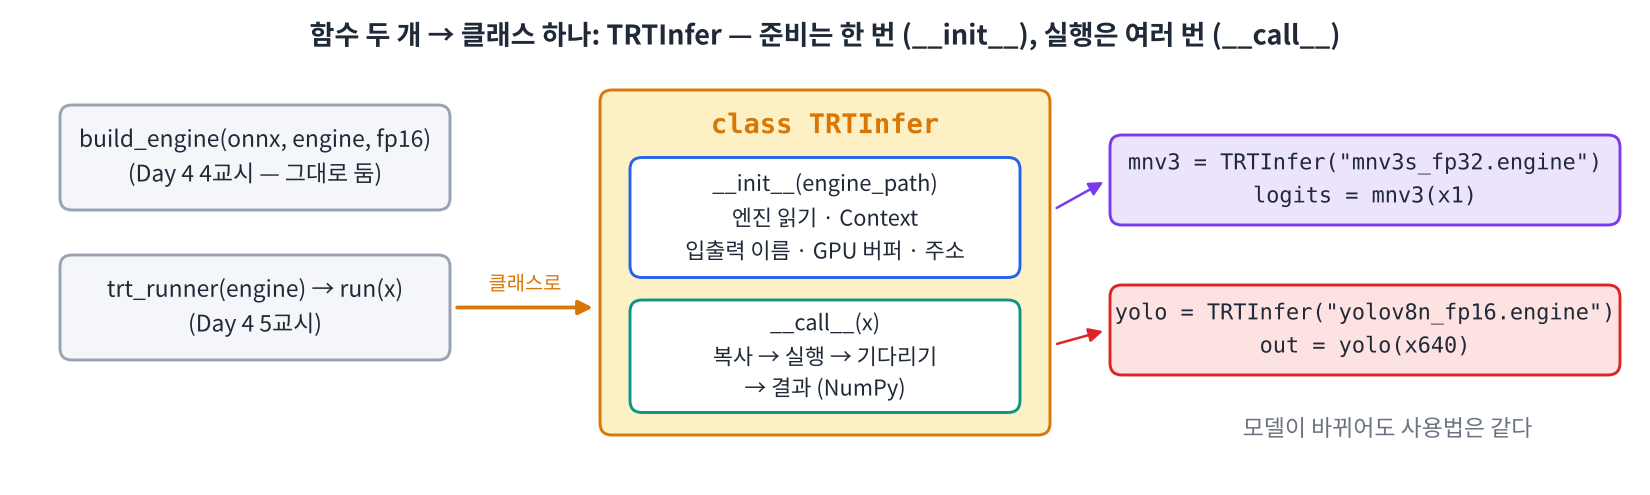

In [ ]:
#@title 🖼 그림 — TRTInfer — 준비는 한 번, 실행은 여러 번
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f1_class.png", embed=True, width=880))

**문제 1-1** `TRTInfer` 를 완성하세요. `__init__` 은 엔진을 읽고 **모든 입출력 텐서**마다 GPU 버퍼를 만들어 주소를 알려 둡니다. `__call__` 은 입력을 복사하고 실행한 뒤 첫 번째 출력을 NumPy 로 돌려줍니다. (Day 4 5-3 과 같은 일 — 자리만 옮김)

In [ ]:
class TRTInfer:
    def __init__(self, engine_path):
        self.engine = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
        self.context = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.inputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT]
        self.outputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT]
        self.buf = {n: torch.empty(tuple(self.engine.get_tensor_shape(n)), dtype=torch.float32, device="cuda") for n in names}
        for n in names:
            self.context.set_tensor_address(n, self.buf[n].____())
        self.input_shape = tuple(self.engine.get_tensor_shape(self.inputs[0]))

    def __call__(self, x):
        self.buf[self.inputs[0]].copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))
        self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        torch.cuda.synchronize()
        return self.buf[self.outputs[____]].cpu().numpy()

    def __repr__(self):
        return f"TRTInfer(in={self.inputs} {self.input_shape}, out={self.outputs})"

print("TRTInfer 정의 완료 — 메서드:", [m for m in TRTInfer.__dict__ if m.startswith("__") and m.endswith("__") and callable(TRTInfer.__dict__[m])])

In [ ]:
assert "__init__" in TRTInfer.__dict__ and "__call__" in TRTInfer.__dict__
print("✅ TRTInfer 정의 — 아래 1-2 에서 진짜 엔진으로 확인")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmNsYXNzIFRSVEluZmVyOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGVu"
    "Z2luZV9wYXRoKToKICAgICAgICBzZWxmLmVuZ2luZSA9IFJVTlRJTUUuZGVzZXJpYWxpemVfY3VkYV9lbmdpbmUo"
    "b3BlbihlbmdpbmVfcGF0aCwgInJiIikucmVhZCgpKQogICAgICAgIHNlbGYuY29udGV4dCA9IHNlbGYuZW5naW5l"
    "LmNyZWF0ZV9leGVjdXRpb25fY29udGV4dCgpCiAgICAgICAgbmFtZXMgPSBbc2VsZi5lbmdpbmUuZ2V0X3RlbnNv"
    "cl9uYW1lKGkpIGZvciBpIGluIHJhbmdlKHNlbGYuZW5naW5lLm51bV9pb190ZW5zb3JzKV0KICAgICAgICBzZWxm"
    "LmlucHV0cyA9IFtuIGZvciBuIGluIG5hbWVzIGlmIHNlbGYuZW5naW5lLmdldF90ZW5zb3JfbW9kZShuKSA9PSB0"
    "cnQuVGVuc29ySU9Nb2RlLklOUFVUXQogICAgICAgIHNlbGYub3V0cHV0cyA9IFtuIGZvciBuIGluIG5hbWVzIGlm"
    "IHNlbGYuZW5naW5lLmdldF90ZW5zb3JfbW9kZShuKSA9PSB0cnQuVGVuc29ySU9Nb2RlLk9VVFBVVF0KICAgICAg"
    "ICBzZWxmLmJ1ZiA9IHtuOiB0b3JjaC5lbXB0eSh0dXBsZShzZWxmLmVuZ2luZS5nZXRfdGVuc29yX3NoYXBlKG4p"
    "KSwgZHR5cGU9dG9yY2guZmxvYXQzMiwgZGV2aWNlPSJjdWRhIikgZm9yIG4gaW4gbmFtZXN9CiAgICAgICAgZm9y"
    "IG4gaW4gbmFtZXM6CiAgICAgICAgICAgIHNlbGYuY29udGV4dC5zZXRfdGVuc29yX2FkZHJlc3Mobiwgc2VsZi5i"
    "dWZbbl0uZGF0YV9wdHIoKSkKICAgICAgICBzZWxmLmlucHV0X3NoYXBlID0gdHVwbGUoc2VsZi5lbmdpbmUuZ2V0"
    "X3RlbnNvcl9zaGFwZShzZWxmLmlucHV0c1swXSkpCgogICAgZGVmIF9fY2FsbF9fKHNlbGYsIHgpOgogICAgICAg"
    "IHNlbGYuYnVmW3NlbGYuaW5wdXRzWzBdXS5jb3B5Xyh0b3JjaC5mcm9tX251bXB5KG5wLmFzY29udGlndW91c2Fy"
    "cmF5KHgsIGR0eXBlPW5wLmZsb2F0MzIpKSkKICAgICAgICBzZWxmLmNvbnRleHQuZXhlY3V0ZV9hc3luY192Myh0"
    "b3JjaC5jdWRhLmN1cnJlbnRfc3RyZWFtKCkuY3VkYV9zdHJlYW0pCiAgICAgICAgdG9yY2guY3VkYS5zeW5jaHJv"
    "bml6ZSgpCiAgICAgICAgcmV0dXJuIHNlbGYuYnVmW3NlbGYub3V0cHV0c1swXV0uY3B1KCkubnVtcHkoKQoKICAg"
    "IGRlZiBfX3JlcHJfXyhzZWxmKToKICAgICAgICByZXR1cm4gZiJUUlRJbmZlcihpbj17c2VsZi5pbnB1dHN9IHtz"
    "ZWxmLmlucHV0X3NoYXBlfSwgb3V0PXtzZWxmLm91dHB1dHN9KSIKCnByaW50KCJUUlRJbmZlciDsoJXsnZgg7JmE"
    "66OMIOKAlCDrqZTshJzrk5w6IiwgW20gZm9yIG0gaW4gVFJUSW5mZXIuX19kaWN0X18gaWYgbS5zdGFydHN3aXRo"
    "KCJfXyIpIGFuZCBtLmVuZHN3aXRoKCJfXyIpIGFuZCBjYWxsYWJsZShUUlRJbmZlci5fX2RpY3RfX1ttXSldKQoK"
    "8J+SoSDtlbTshKQKX19jYWxsX18g7J20IOyeiOycvOuptCDqsJ3ssrTrpbwg7ZWo7IiY7LKY65+8IOu2gOulvCDs"
    "iJgg7J6I7Iq164uI64ukOiB5b2xvKHgpLiDqt7jrnpjshJwgT1JUIOyEuOyFmOydhCDqsJDsi7wg7ZWo7IiY7JmA"
    "ICfqsJnsnYAg66qo7JaRJyDsnLzroZwg67CU6r+UIOuBvOyauCDsiJgg7J6I7Iq164uI64ukICg16rWQ7IucKS4="
).decode("utf-8"))

**문제 1-2** **mnv3s 로 확인** — Day 4 와 같은 배치 1 ONNX 를 만들고 FP32 엔진을 빌드 (`build_once` — 이미 있으면 건너뜀) 한 뒤, `TRTInfer` 결과를 ORT CPU 와 비교하세요.

In [ ]:
torch.onnx.export(make_mnv3s(), torch.randn(1, 3, 224, 224), "mnv3s_b1.onnx", input_names=["input"], output_names=["logits"],
                  opset_version=17, **EXPORT_KW)
build_once("mnv3s_b1.onnx", "mnv3s_fp32.engine")
mnv3 = ____("mnv3s_fp32.engine")
x1 = np.random.rand(1, 3, 224, 224).astype(np.float32)
ref = ort.InferenceSession("mnv3s_b1.onnx", providers=CPU).run(None, {"input": x1})[0]
print(mnv3, "| 최대 차이", f"{np.abs(mnv3(x1) - ref).max():.1e}")

In [ ]:
assert mnv3.input_shape == (1, 3, 224, 224) and mnv3(x1).shape == (1, 1000) and np.allclose(mnv3(x1), ref, atol=1e-3)
print("✅ TRTInfer = Day 4 trt_runner 와 같은 답")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACnRvcmNoLm9ubnguZXhwb3J0KG1ha2VfbW52M3MoKSwgdG9yY2gucmFu"
    "ZG4oMSwgMywgMjI0LCAyMjQpLCAibW52M3NfYjEub25ueCIsIGlucHV0X25hbWVzPVsiaW5wdXQiXSwgb3V0cHV0"
    "X25hbWVzPVsibG9naXRzIl0sCiAgICAgICAgICAgICAgICAgIG9wc2V0X3ZlcnNpb249MTcsICoqRVhQT1JUX0tX"
    "KQpidWlsZF9vbmNlKCJtbnYzc19iMS5vbm54IiwgIm1udjNzX2ZwMzIuZW5naW5lIikKbW52MyA9IFRSVEluZmVy"
    "KCJtbnYzc19mcDMyLmVuZ2luZSIpCngxID0gbnAucmFuZG9tLnJhbmQoMSwgMywgMjI0LCAyMjQpLmFzdHlwZShu"
    "cC5mbG9hdDMyKQpyZWYgPSBvcnQuSW5mZXJlbmNlU2Vzc2lvbigibW52M3NfYjEub25ueCIsIHByb3ZpZGVycz1D"
    "UFUpLnJ1bihOb25lLCB7ImlucHV0IjogeDF9KVswXQpwcmludChtbnYzLCAifCDstZzrjIAg7LCo7J20IiwgZiJ7"
    "bnAuYWJzKG1udjMoeDEpIC0gcmVmKS5tYXgoKTouMWV9IikKCvCfkqEg7ZW07ISkCuqwmeydgCBDb2xhYiDshLjs"
    "hZjsl5DshJwgRGF5IDQg7JeU7KeEIO2MjOydvOydtCDrgqjslYQg7J6I7KeA64qUIOyViuycvOuvgOuhnCAo65+w"
    "7YOA7J6E7J20IOyDiOuhnCDsi5zsnpHrkKgpIO2VnCDrsojsnYAg67mM65Oc7ZWp64uI64ukLiDslb0gMeu2hC4="
).decode("utf-8"))

#### 📌 1교시 정리

- `TRTInfer(engine)` — `__init__`: 엔진 · Context · 입출력 이름 · GPU 버퍼 · 주소 (한 번), `__call__(x)`: 복사 → 실행 → 기다리기 → NumPy.
- `build_once` — 엔진은 오래 걸리니 있으면 다시 만들지 않는다.

## 2교시 — YOLOv8n 엔진 만들기 · VB 전처리 · 후처리 연결

VB Day 5 에서 export 한 것과 같은 `yolov8n.onnx` (입력 `images` (1, 3, 640, 640), 출력 `output0` (1, 84, 8400)) 를 FP16 엔진으로 바꿉니다. 앞의 **letterbox** 와 뒤의 **decode_yolo** (NMS 포함) 는 VB 함수를 그대로 씁니다.

> 🎬 **애니메이션** [D5-2 YOLOv8n 엔진 · 입출력](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

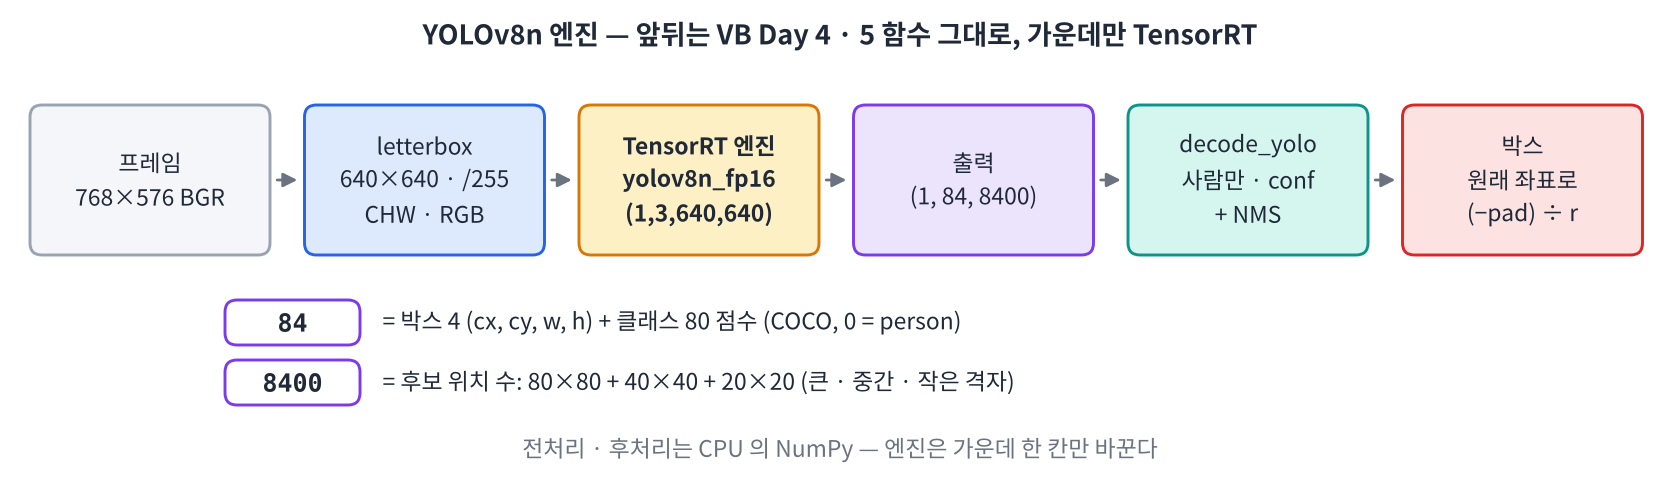

In [ ]:
#@title 🖼 그림 — YOLOv8n 엔진 — 앞뒤는 VB 함수 그대로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f2_yolo_io.png", embed=True, width=900))

**문제 2-1** YOLOv8n 을 **FP16** 엔진 `yolov8n_fp16.engine` 으로 빌드하고 `TRTInfer` 로 읽어 입출력을 확인하세요. **수 분 걸립니다** — 기다리는 동안 그림의 84 · 8400 을 읽어 두세요.

In [ ]:
print("ONNX 노드", len(onnx.load(YOLO_ONNX).graph.node), "개")
build_once(YOLO_ONNX, "yolov8n_fp16.engine", fp16=____)
yolo16 = TRTInfer("yolov8n_fp16.engine")
print(yolo16, "| 출력", tuple(yolo16.buf[yolo16.outputs[0]].shape), "| 파일", f"{os.path.getsize('yolov8n_fp16.engine') / 1e6:.1f} MB")

In [ ]:
assert yolo16.inputs == ["images"] and yolo16.input_shape == (1, 3, 640, 640) and tuple(yolo16.buf["output0"].shape) == (1, 84, 8400)
print("✅ 입력 images (1, 3, 640, 640) → 출력 output0 (1, 84, 8400) — VB 와 같은 모양")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACnByaW50KCJPTk5YIOuFuOuTnCIsIGxlbihvbm54LmxvYWQoWU9MT19P"
    "Tk5YKS5ncmFwaC5ub2RlKSwgIuqwnCIpCmJ1aWxkX29uY2UoWU9MT19PTk5YLCAieW9sb3Y4bl9mcDE2LmVuZ2lu"
    "ZSIsIGZwMTY9VHJ1ZSkKeW9sbzE2ID0gVFJUSW5mZXIoInlvbG92OG5fZnAxNi5lbmdpbmUiKQpwcmludCh5b2xv"
    "MTYsICJ8IOy2nOugpSIsIHR1cGxlKHlvbG8xNi5idWZbeW9sbzE2Lm91dHB1dHNbMF1dLnNoYXBlKSwgInwg7YyM"
    "7J28IiwgZiJ7b3MucGF0aC5nZXRzaXplKCd5b2xvdjhuX2ZwMTYuZW5naW5lJykgLyAxZTY6LjFmfSBNQiIpCgrw"
    "n5KhIO2VtOyEpAo4NCA9IOuwleyKpCA0ICsgQ09DTyA4MCDtgbTrnpjsiqQg7KCQ7IiYLCA4NDAwID0gODDDlzgw"
    "ICsgNDDDlzQwICsgMjDDlzIwIO2bhOuztCDsnITsuZguIOyXlOynhOydtCDrsJTrgIzslrTrj4Qg7J20IOuqqOyW"
    "keydgCDqt7jrjIDroZwg4oCUIOq3uOuemOyEnCDtm4Tsspjrpqzrpbwg6re464yA66GcIOyTuCDsiJgg7J6I7Iq1"
    "64uI64ukLg=="
).decode("utf-8"))

**문제 2-2** **탐지 함수** — 프레임 (BGR) 과 '추론기' `infer` (x → 출력) 를 받아 원래 좌표의 사람 박스 · 점수를 돌려주는 `detect(frame, infer, conf, iou_thr)` 를 완성하세요. VB 의 `detect_onnx` 에서 `sess.run(...)` 만 `infer(x)` 로 바뀐 것입니다. ORT CPU 와 TensorRT FP16 으로 `frame200` 을 탐지해 비교합니다.

In [ ]:
def detect(frame, infer, conf=0.25, iou_thr=0.7):
    lb, r, (pl, pt) = letterbox(frame)
    x = (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32)     # BGR→RGB · CHW · 0~1
    out = ____(x)
    boxes, scores = decode_yolo(out, conf, iou_thr)
    boxes = (boxes - [pl, pt, pl, pt]) / ____                                  # letterbox 되돌리기
    H, W = frame.shape[:2]
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, W); boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, H)
    return boxes, scores

sess_cpu = ort.InferenceSession(YOLO_ONNX, providers=CPU)
ort_infer = lambda x: sess_cpu.run(None, {"images": x})[0]                    # ORT 세션도 '같은 모양' 의 함수로
b_ort, s_ort = detect(frame200, ort_infer)
b_trt, s_trt = detect(frame200, yolo16)
m_iou = iou_matrix(b_trt, b_ort).max(1) if len(b_trt) and len(b_ort) else np.array([0.0])
print(f"ORT CPU {len(b_ort)}명 · TensorRT FP16 {len(b_trt)}명 | 짝 IoU 최소 {m_iou.min():.4f} · 평균 {m_iou.mean():.4f}")

In [ ]:
assert len(b_ort) > 0 and abs(len(b_trt) - len(b_ort)) <= 1 and np.median(m_iou) > 0.9
print("✅ 같은 사람을 거의 같은 박스로 — 엔진만 바꿨다")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBkZXRlY3QoZnJhbWUsIGluZmVyLCBjb25mPTAuMjUsIGlvdV90"
    "aHI9MC43KToKICAgIGxiLCByLCAocGwsIHB0KSA9IGxldHRlcmJveChmcmFtZSkKICAgIHggPSAobGJbLi4uLCA6"
    "Oi0xXS50cmFuc3Bvc2UoMiwgMCwgMSlbTm9uZV0gLyAyNTUuMCkuYXN0eXBlKG5wLmZsb2F0MzIpICAgICAjIEJH"
    "UuKGklJHQiDCtyBDSFcgwrcgMH4xCiAgICBvdXQgPSBpbmZlcih4KQogICAgYm94ZXMsIHNjb3JlcyA9IGRlY29k"
    "ZV95b2xvKG91dCwgY29uZiwgaW91X3RocikKICAgIGJveGVzID0gKGJveGVzIC0gW3BsLCBwdCwgcGwsIHB0XSkg"
    "LyByICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjIGxldHRlcmJveCDrkJjrj4zrpqzquLAK"
    "ICAgIEgsIFcgPSBmcmFtZS5zaGFwZVs6Ml0KICAgIGJveGVzWzosIFswLCAyXV0gPSBib3hlc1s6LCBbMCwgMl1d"
    "LmNsaXAoMCwgVyk7IGJveGVzWzosIFsxLCAzXV0gPSBib3hlc1s6LCBbMSwgM11dLmNsaXAoMCwgSCkKICAgIHJl"
    "dHVybiBib3hlcywgc2NvcmVzCgpzZXNzX2NwdSA9IG9ydC5JbmZlcmVuY2VTZXNzaW9uKFlPTE9fT05OWCwgcHJv"
    "dmlkZXJzPUNQVSkKb3J0X2luZmVyID0gbGFtYmRhIHg6IHNlc3NfY3B1LnJ1bihOb25lLCB7ImltYWdlcyI6IHh9"
    "KVswXSAgICAgICAgICAgICAgICAgICAgIyBPUlQg7IS47IWY64+EICfqsJnsnYAg66qo7JaRJyDsnZgg7ZWo7IiY"
    "66GcCmJfb3J0LCBzX29ydCA9IGRldGVjdChmcmFtZTIwMCwgb3J0X2luZmVyKQpiX3RydCwgc190cnQgPSBkZXRl"
    "Y3QoZnJhbWUyMDAsIHlvbG8xNikKbV9pb3UgPSBpb3VfbWF0cml4KGJfdHJ0LCBiX29ydCkubWF4KDEpIGlmIGxl"
    "bihiX3RydCkgYW5kIGxlbihiX29ydCkgZWxzZSBucC5hcnJheShbMC4wXSkKcHJpbnQoZiJPUlQgQ1BVIHtsZW4o"
    "Yl9vcnQpfeuqhSDCtyBUZW5zb3JSVCBGUDE2IHtsZW4oYl90cnQpfeuqhSB8IOynnSBJb1Ug7LWc7IaMIHttX2lv"
    "dS5taW4oKTouNGZ9IMK3IO2Pieq3oCB7bV9pb3UubWVhbigpOi40Zn0iKQoK8J+SoSDtlbTshKQKaW5mZXIg66W8"
    "IOyduOyekOuhnCDrsJvsnLzrqbQgT1JUIMK3IFRlbnNvclJUIEZQMzIgwrcgRlAxNiDslrTripAg6rKD7J2065Og"
    "IOqwmeydgCBkZXRlY3Qg66W8IOyUgeuLiOuLpCDigJQg7Jik64qYIO2VmOujqOydmCDshKTqs4Qg7ZW17IusLgpG"
    "UDE2IOydgCDsoJDsiJjqsIAg7KGw6riIIOuLrOudvCBjb25mIOqyveqzhCAoMC4yNSkg6re87LKY7J2YIOyCrOue"
    "jOydtCDtlZjrgpgg7IOd6riw6rGw64KYIOu5oOyniCDsiJgg7J6I7Iq164uI64ukICjqt7jrnpjshJwgwrExIO2X"
    "iOyaqSku"
).decode("utf-8"))

In [ ]:
vis = frame200.copy()
for b in b_ort.astype(int):
    cv2.rectangle(vis, tuple(b[:2]), tuple(b[2:]), (0, 200, 0), 4)            # ORT CPU: 초록 (두껍게)
for b in b_trt.astype(int):
    cv2.rectangle(vis, tuple(b[:2]), tuple(b[2:]), (0, 0, 255), 1)            # TensorRT FP16: 빨강 (얇게)
show([vis], ["초록 = ORT CPU · 빨강 = TensorRT FP16 — 겹쳐 보이면 같은 결과"], cols=1, size=7)

#### 📌 2교시 정리

- `build_once(YOLO_ONNX, "yolov8n_fp16.engine", fp16=True)` → `TRTInfer` — 출력 (1, 84, 8400) 그대로.
- `detect(frame, infer)` — letterbox → infer → decode_yolo → 원래 좌표. **infer 만 바꿔 끼운다.**

## 3교시 — 정확도 확인: ORT vs TensorRT FP32 vs FP16

사진 한 장이 같아 보여도 **전체 성능**이 같은지는 숫자로 봐야 합니다. VB Day 4 의 Penn-Fudan 170장 · 정답 박스와 `evaluate_ap` 로 세 실행기의 **AP50 · mAP50-95** 를 비교합니다.

> 🎬 **애니메이션** [D5-3 FP16 정확도 — AP 비교](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

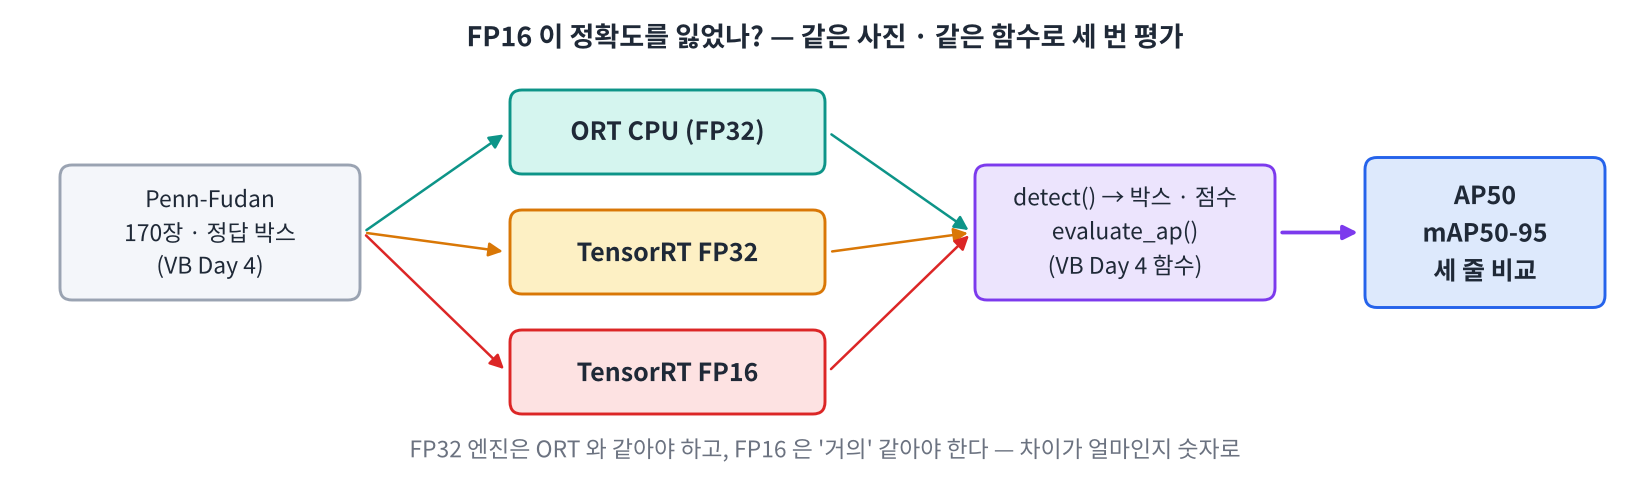

In [ ]:
#@title 🖼 그림 — 같은 사진 · 같은 함수로 세 번 평가
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f3_map.png", embed=True, width=880))

**문제 3-1** FP32 엔진도 만들고 (`build_once`, 수 분), 세 실행기로 170장을 탐지해 AP 표를 만드세요. AP 를 잴 때는 점수가 낮은 박스도 남겨야 하므로 `conf=0.01`. 박스 · 점수를 `[x1, y1, x2, y2, score]` 한 줄로 붙입니다.

In [ ]:
build_once(YOLO_ONNX, "yolov8n_fp32.engine", fp16=False)
yolo32 = TRTInfer("yolov8n_fp32.engine")
INFERS = {"ORT CPU": ort_infer, "TRT FP32": yolo32, "TRT FP16": yolo16}
imgs = [cv2.imread(p) for p in img_paths]
ap_rows = []
for name, f in INFERS.items():
    t0 = time.time()
    dets = []
    for im in imgs:
        b, s = detect(im, f, conf=0.01)
        dets.append(np.concatenate([b, s[:, None]], 1))
    ap_rows.append({"runtime": name, "AP50": evaluate_ap(dets, ____), "mAP50-95": map_50_95(dets, gts),
                    "n_det": sum(len(d) for d in dets), "sec": time.time() - t0})
df_ap = pd.DataFrame(ap_rows)
display(df_ap)

In [ ]:
d32 = abs(df_ap["AP50"][1] - df_ap["AP50"][0]); d16 = abs(df_ap["AP50"][2] - df_ap["AP50"][0])
assert df_ap.runtime.tolist() == ["ORT CPU", "TRT FP32", "TRT FP16"] and df_ap["AP50"][0] > 0.5 and d32 < 0.01 and d16 < 0.03
print(f"✅ AP50 차이 — FP32 {d32:.4f} · FP16 {d16:.4f} : FP16 으로 바꿔도 정확도는 거의 그대로")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmJ1aWxkX29uY2UoWU9MT19PTk5YLCAieW9sb3Y4bl9mcDMyLmVuZ2lu"
    "ZSIsIGZwMTY9RmFsc2UpCnlvbG8zMiA9IFRSVEluZmVyKCJ5b2xvdjhuX2ZwMzIuZW5naW5lIikKSU5GRVJTID0g"
    "eyJPUlQgQ1BVIjogb3J0X2luZmVyLCAiVFJUIEZQMzIiOiB5b2xvMzIsICJUUlQgRlAxNiI6IHlvbG8xNn0KaW1n"
    "cyA9IFtjdjIuaW1yZWFkKHApIGZvciBwIGluIGltZ19wYXRoc10KYXBfcm93cyA9IFtdCmZvciBuYW1lLCBmIGlu"
    "IElORkVSUy5pdGVtcygpOgogICAgdDAgPSB0aW1lLnRpbWUoKQogICAgZGV0cyA9IFtdCiAgICBmb3IgaW0gaW4g"
    "aW1nczoKICAgICAgICBiLCBzID0gZGV0ZWN0KGltLCBmLCBjb25mPTAuMDEpCiAgICAgICAgZGV0cy5hcHBlbmQo"
    "bnAuY29uY2F0ZW5hdGUoW2IsIHNbOiwgTm9uZV1dLCAxKSkKICAgIGFwX3Jvd3MuYXBwZW5kKHsicnVudGltZSI6"
    "IG5hbWUsICJBUDUwIjogZXZhbHVhdGVfYXAoZGV0cywgZ3RzKSwgIm1BUDUwLTk1IjogbWFwXzUwXzk1KGRldHMs"
    "IGd0cyksCiAgICAgICAgICAgICAgICAgICAgIm5fZGV0Ijogc3VtKGxlbihkKSBmb3IgZCBpbiBkZXRzKSwgInNl"
    "YyI6IHRpbWUudGltZSgpIC0gdDB9KQpkZl9hcCA9IHBkLkRhdGFGcmFtZShhcF9yb3dzKQpkaXNwbGF5KGRmX2Fw"
    "KQoK8J+SoSDtlbTshKQKc2VjIOyXtOydgCAxNzDsnqUg7YOQ7KeAICsg7KCE7LKY66asIMK3IO2bhOyymOumrCDs"
    "oITssrQg7Iuc6rCEIOKAlCBPUlQgQ1BVIOuKlCDstpTroaAg7J6Q7LK06rCAIOq4uOqzoCwgVGVuc29yUlQg64qU"
    "IOynp+yKteuLiOuLpC4KUGVubi1GdWRhbiDsnZgg7KCV64u17JeQ64qUIOyekeqxsOuCmCDqsIDroKTsp4Qg7IKs"
    "656M7J20IOu5oOyguCDsnojslrQgQVA1MCDsnbQgMS4wIOydtCDrkJjsp4DripQg7JWK7Iq164uI64ukIChWQiBE"
    "YXkgNCDsmYAg6rCZ7J2AIOydtOycoCku"
).decode("utf-8"))

**문제 3-2** **박스로 확인** — FP16 의 박스가 FP32 와 얼마나 같은지 사진 몇 장에서 봅니다. 각 FP16 박스와 가장 겹치는 FP32 박스의 IoU 를 모아 최소값 · 평균을 구하세요 (`conf=0.25`, 처음 20장).

In [ ]:
pair_iou = []
for im in imgs[:20]:
    b32, _ = detect(im, yolo32); b16, _ = detect(im, yolo16)
    if len(b32) and len(b16):
        pair_iou += list(iou_matrix(b16, b32).____(1))
pair_iou = np.array(pair_iou)
print(f"FP16 박스 {len(pair_iou)}개 · FP32 와 짝 IoU 최소 {pair_iou.min():.4f} · 평균 {pair_iou.mean():.4f} · 0.95 이상 {np.mean(pair_iou >= 0.95):.0%}")

In [ ]:
assert len(pair_iou) > 10 and np.median(pair_iou) > 0.95; print("✅ 박스 단위로도 거의 같다")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACnBhaXJfaW91ID0gW10KZm9yIGltIGluIGltZ3NbOjIwXToKICAgIGIz"
    "MiwgXyA9IGRldGVjdChpbSwgeW9sbzMyKTsgYjE2LCBfID0gZGV0ZWN0KGltLCB5b2xvMTYpCiAgICBpZiBsZW4o"
    "YjMyKSBhbmQgbGVuKGIxNik6CiAgICAgICAgcGFpcl9pb3UgKz0gbGlzdChpb3VfbWF0cml4KGIxNiwgYjMyKS5t"
    "YXgoMSkpCnBhaXJfaW91ID0gbnAuYXJyYXkocGFpcl9pb3UpCnByaW50KGYiRlAxNiDrsJXsiqQge2xlbihwYWly"
    "X2lvdSl96rCcIMK3IEZQMzIg7JmAIOynnSBJb1Ug7LWc7IaMIHtwYWlyX2lvdS5taW4oKTouNGZ9IMK3IO2Pieq3"
    "oCB7cGFpcl9pb3UubWVhbigpOi40Zn0gwrcgMC45NSDsnbTsg4Ege25wLm1lYW4ocGFpcl9pb3UgPj0gMC45NSk6"
    "LjAlfSIpCgrwn5KhIO2VtOyEpArstZzshozqsJLsnbQg64Ku6rKMIOuCmOyYpOuptCDqt7gg67CV7Iqk64qUIEZQ"
    "MTYg7JeQ7ISc66eMIOyDneq4tCAo65iQ64qUIOqyveqzhOyXkOyEnCDqsIjrnbzsp4QpIOuwleyKpCDigJQgY29u"
    "ZiDqsr3qs4Qg6re87LKY7J2YIOyCrOuejOyeheuLiOuLpC4g7Y+J6regIMK3IOu5hOycqOuhnCDsoITssrTrpbwg"
    "7YyQ64uo7ZWY7IS47JqULg=="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- AP 를 `conf=0.25` 로 잼 → 낮은 점수 박스가 잘려 recall 곡선이 짧아지고 AP 가 낮게 나옵니다. AP 는 낮은 conf (0.01 등) 로.
- 엔진마다 전처리를 다르게 함 → 실행기 비교가 아니라 전처리 비교가 됩니다. **같은 detect** 를 씁니다.
- FP32 엔진과 ORT 의 AP 가 다르게 나옴 → 대개 입력 dtype · 채널 순서 (BGR/RGB) 실수. 같은 사진으로 출력을 먼저 비교.

#### 📌 3교시 정리

- 같은 사진 · 같은 `detect` · 같은 `evaluate_ap` 로 세 실행기 비교 → FP32 = ORT, FP16 ≈ ORT.
- 정확도는 전체 지표 (AP) + 박스 단위 (짝 IoU) 두 가지로 본다.

## 4교시 — 시간 나눠 재기: 전처리 · 추론 · 후처리 · 그리기

엔진은 빨라졌습니다. 그런데 **영상 한 프레임**을 처리하는 시간도 그만큼 빨라졌을까요? 한 프레임을 네 조각으로 나눠 ORT CPU 와 TensorRT FP16 을 비교합니다.

> 🎬 **애니메이션** [D5-4 네 조각 · 다음 병목](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

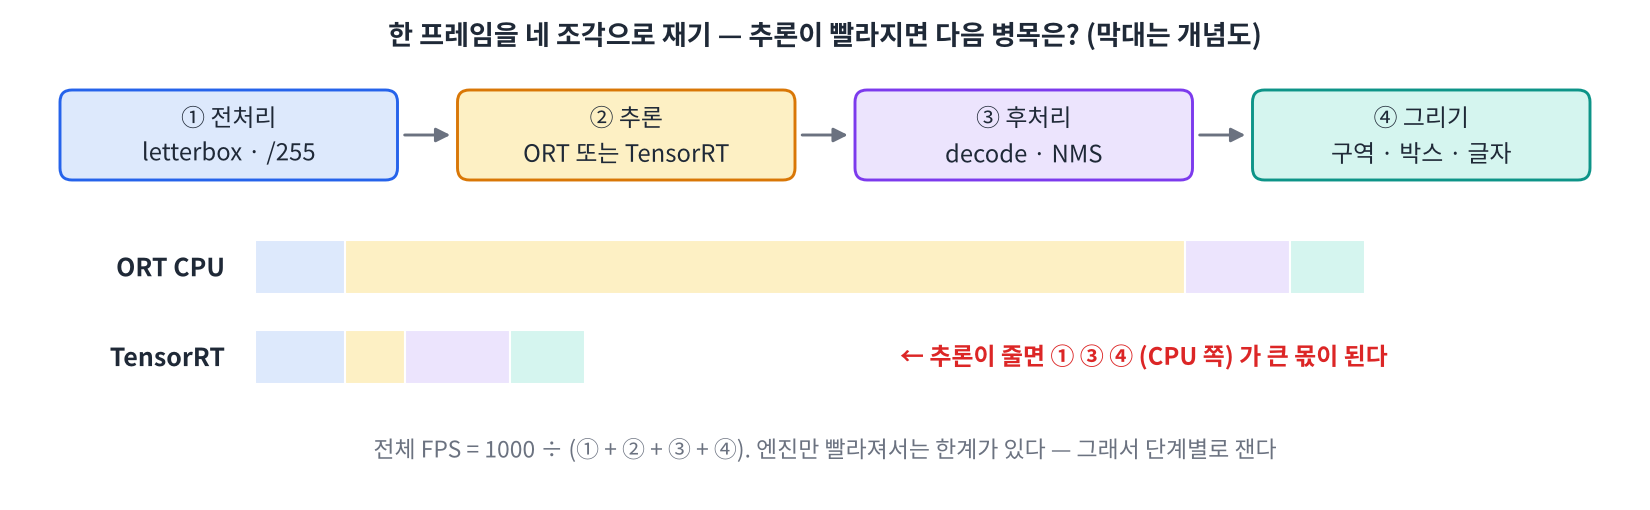

In [ ]:
#@title 🖼 그림 — 한 프레임을 네 조각으로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f4_stages.png", embed=True, width=880))

**문제 4-1** `time_stages(frame, infer)` 를 완성하세요. 네 조각 각각의 시간 (ms) 을 딕셔너리로 돌려줍니다. 영상의 첫 50 프레임으로 ORT CPU · TensorRT FP16 의 평균을 표로 만듭니다.

In [ ]:
def time_stages(frame, infer, conf=0.25):
    T = {}
    t0 = time.perf_counter()
    lb, r, (pl, pt) = letterbox(frame)
    x = (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32)
    t1 = time.perf_counter()
    out = infer(x)
    t2 = time.perf_counter()
    boxes, scores = decode_yolo(out, conf, 0.7)
    boxes = (boxes - [pl, pt, pl, pt]) / r
    inside = [in_zone(p) for p in foot_points(boxes)]
    t3 = time.perf_counter()
    draw_result(frame, boxes, inside, alarm=any(inside))
    t4 = time.perf_counter()
    T["pre"], T["infer"], T["post"], T["draw"] = [(b - a) * 1000 for a, b in [(t0, t1), (t1, t2), (t2, ____), (t3, t4)]]
    return T

cap = cv2.VideoCapture(VIDEO); frames50 = [cap.read()[1] for _ in range(50)]; cap.release()
stage_rows = []
for name, f in [("ORT CPU", ort_infer), ("TRT FP16", yolo16)]:
    for fr in frames50[:5]:
        time_stages(fr, f)                                   # warm-up
    ts = pd.DataFrame([time_stages(fr, f) for fr in frames50]).mean()
    stage_rows.append({"runtime": name, **ts.to_dict(), "total": ts.____()})
df_st = pd.DataFrame(stage_rows).set_index("runtime")
df_st["fps"] = 1000 / df_st["total"]
display(df_st)

In [ ]:
assert list(df_st.index) == ["ORT CPU", "TRT FP16"] and np.allclose(df_st[["pre", "infer", "post", "draw"]].sum(1), df_st.total)
print("✅ 프레임당 — ORT CPU", f"{df_st.total.iloc[0]:.1f} ms · TensorRT FP16 {df_st.total.iloc[1]:.1f} ms")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmRlZiB0aW1lX3N0YWdlcyhmcmFtZSwgaW5mZXIsIGNvbmY9MC4yNSk6"
    "CiAgICBUID0ge30KICAgIHQwID0gdGltZS5wZXJmX2NvdW50ZXIoKQogICAgbGIsIHIsIChwbCwgcHQpID0gbGV0"
    "dGVyYm94KGZyYW1lKQogICAgeCA9IChsYlsuLi4sIDo6LTFdLnRyYW5zcG9zZSgyLCAwLCAxKVtOb25lXSAvIDI1"
    "NS4wKS5hc3R5cGUobnAuZmxvYXQzMikKICAgIHQxID0gdGltZS5wZXJmX2NvdW50ZXIoKQogICAgb3V0ID0gaW5m"
    "ZXIoeCkKICAgIHQyID0gdGltZS5wZXJmX2NvdW50ZXIoKQogICAgYm94ZXMsIHNjb3JlcyA9IGRlY29kZV95b2xv"
    "KG91dCwgY29uZiwgMC43KQogICAgYm94ZXMgPSAoYm94ZXMgLSBbcGwsIHB0LCBwbCwgcHRdKSAvIHIKICAgIGlu"
    "c2lkZSA9IFtpbl96b25lKHApIGZvciBwIGluIGZvb3RfcG9pbnRzKGJveGVzKV0KICAgIHQzID0gdGltZS5wZXJm"
    "X2NvdW50ZXIoKQogICAgZHJhd19yZXN1bHQoZnJhbWUsIGJveGVzLCBpbnNpZGUsIGFsYXJtPWFueShpbnNpZGUp"
    "KQogICAgdDQgPSB0aW1lLnBlcmZfY291bnRlcigpCiAgICBUWyJwcmUiXSwgVFsiaW5mZXIiXSwgVFsicG9zdCJd"
    "LCBUWyJkcmF3Il0gPSBbKGIgLSBhKSAqIDEwMDAgZm9yIGEsIGIgaW4gWyh0MCwgdDEpLCAodDEsIHQyKSwgKHQy"
    "LCB0MyksICh0MywgdDQpXV0KICAgIHJldHVybiBUCgpjYXAgPSBjdjIuVmlkZW9DYXB0dXJlKFZJREVPKTsgZnJh"
    "bWVzNTAgPSBbY2FwLnJlYWQoKVsxXSBmb3IgXyBpbiByYW5nZSg1MCldOyBjYXAucmVsZWFzZSgpCnN0YWdlX3Jv"
    "d3MgPSBbXQpmb3IgbmFtZSwgZiBpbiBbKCJPUlQgQ1BVIiwgb3J0X2luZmVyKSwgKCJUUlQgRlAxNiIsIHlvbG8x"
    "NildOgogICAgZm9yIGZyIGluIGZyYW1lczUwWzo1XToKICAgICAgICB0aW1lX3N0YWdlcyhmciwgZikgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgd2FybS11cAogICAgdHMgPSBwZC5EYXRhRnJhbWUoW3RpbWVf"
    "c3RhZ2VzKGZyLCBmKSBmb3IgZnIgaW4gZnJhbWVzNTBdKS5tZWFuKCkKICAgIHN0YWdlX3Jvd3MuYXBwZW5kKHsi"
    "cnVudGltZSI6IG5hbWUsICoqdHMudG9fZGljdCgpLCAidG90YWwiOiB0cy5zdW0oKX0pCmRmX3N0ID0gcGQuRGF0"
    "YUZyYW1lKHN0YWdlX3Jvd3MpLnNldF9pbmRleCgicnVudGltZSIpCmRmX3N0WyJmcHMiXSA9IDEwMDAgLyBkZl9z"
    "dFsidG90YWwiXQpkaXNwbGF5KGRmX3N0KQoK8J+SoSDtlbTshKQKVGVuc29yUlQg7J2YIGluZmVyIOyXkOuKlCBD"
    "UFUg4oaSIEdQVSDrs7Xsgqwgwrcg7Iuk7ZaJIMK3IEdQVSDihpIgQ1BVIOuzteyCrOqwgCDrqqjrkZAg65Ok7Ja0"
    "IOyeiOyKteuLiOuLpCAoVFJUSW5mZXIuX19jYWxsX18g7KCE7LK0KS4KcHJlIMK3IHBvc3QgwrcgZHJhdyDripQg"
    "65GQIOykhOydtCDruYTsirftlbTslbwg7KCV7IOBIOKAlCDqsJnsnYAgQ1BVIOy9lOuTnOydtOq4sCDrlYzrrLjs"
    "noXri4jri6Qu"
).decode("utf-8"))

**문제 4-2** **다음 병목은?** 두 실행기 각각에서 가장 오래 걸린 조각과 그 비율 (%) 을 구하고, 누적 막대그래프로 그리세요.

In [ ]:
parts = ["pre", "infer", "post", "draw"]
share = df_st[parts].div(df_st["total"], axis=0) * 100
bottleneck = {rt: share.loc[rt].____() for rt in share.index}
print("가장 오래 걸린 조각:", bottleneck)
display(share.round(1))
ax = df_st[parts].plot(kind="barh", stacked=True, figsize=(8, 2.4), color=["#9bb8e8", "#f2c46d", "#c3a6ea", "#8fd8c4"])
ax.set_xlabel("ms / 프레임"); plt.title("한 프레임의 네 조각"); plt.tight_layout(); plt.show()

In [ ]:
assert set(bottleneck) == {"ORT CPU", "TRT FP16"} and bottleneck["ORT CPU"] == share.loc["ORT CPU"].idxmax()
print("✅ ORT CPU 의 병목:", bottleneck["ORT CPU"], "· TensorRT FP16 의 병목:", bottleneck["TRT FP16"])

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACnBhcnRzID0gWyJwcmUiLCAiaW5mZXIiLCAicG9zdCIsICJkcmF3Il0K"
    "c2hhcmUgPSBkZl9zdFtwYXJ0c10uZGl2KGRmX3N0WyJ0b3RhbCJdLCBheGlzPTApICogMTAwCmJvdHRsZW5lY2sg"
    "PSB7cnQ6IHNoYXJlLmxvY1tydF0uaWR4bWF4KCkgZm9yIHJ0IGluIHNoYXJlLmluZGV4fQpwcmludCgi6rCA7J6l"
    "IOyYpOuemCDqsbjrprAg7KGw6rCBOiIsIGJvdHRsZW5lY2spCmRpc3BsYXkoc2hhcmUucm91bmQoMSkpCmF4ID0g"
    "ZGZfc3RbcGFydHNdLnBsb3Qoa2luZD0iYmFyaCIsIHN0YWNrZWQ9VHJ1ZSwgZmlnc2l6ZT0oOCwgMi40KSwgY29s"
    "b3I9WyIjOWJiOGU4IiwgIiNmMmM0NmQiLCAiI2MzYTZlYSIsICIjOGZkOGM0Il0pCmF4LnNldF94bGFiZWwoIm1z"
    "IC8g7ZSE66CI7J6EIik7IHBsdC50aXRsZSgi7ZWcIO2UhOugiOyehOydmCDrhKQg7KGw6rCBIik7IHBsdC50aWdo"
    "dF9sYXlvdXQoKTsgcGx0LnNob3coKQoK8J+SoSDtlbTshKQKT1JUIENQVSDripQgaW5mZXIg6rCAIOuMgOu2gOu2"
    "hC4gVGVuc29yUlQg66GcIOuwlOq+uOuptCBpbmZlciDruYTspJHsnbQg7KSE7Ja0IHByZSDCtyBwb3N0IChOdW1Q"
    "eSDCtyBQeXRob24gTk1TKSDrgpggZHJhdyDqsIAg7YGwIOuqq+ydtCDrkKnri4jri6QuCuuLpOydjOyXkCDqs6Ds"
    "uaAg6rOzOiDsoITsspjrpqzrpbwgR1BVIOuhnCAodG9yY2ggwrcgY3YyLmN1ZGEpLCBOTVMg66W8IOuyoe2EsO2Z"
    "lCDCtyBHUFUg66GcICh0b3JjaHZpc2lvbi5vcHMubm1zKSwg6re466as6riw66W8IOykhOydtOq4sCDigJQg67Cc"
    "7ZGcIOyniOusuCAzIOydmCDsnqzro4zsnoXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- 추론 시간만 보고 'FPS 가 이만큼 나온다' 고 발표 → 실제 파이프라인 FPS 는 네 조각의 합으로 정해집니다.
- 영상 읽기 · 저장 (디스크) 시간을 빼먹음 → 오늘 표에는 없지만 실제 FPS 에는 들어갑니다 (6교시의 파이프라인 FPS).
- warm-up 없이 첫 프레임부터 평균 → TensorRT 첫 실행 준비 시간이 섞입니다.

#### 📌 4교시 정리

- 프레임 시간 = 전처리 + 추론 + 후처리 + 그리기. FPS = 1000 ÷ 합.
- 추론이 빨라지면 **CPU 쪽 (전처리 · 후처리 · 그리기)** 이 새 병목이 된다.

## 5교시 — 미니 프로젝트 ① 이식: 추론기만 교체

VB Day 5 의 위험구역 침입 감지기를 TensorRT 로 옮깁니다. **바꾸는 곳은 탐지에 넘기는 `infer` 하나** — 발 위치 · 구역 판정 · 3프레임 연속 경보 (debounce) · 그리기는 VB 그대로입니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `process_frame` — 프레임 한 장: 탐지 → 발 위치 → 구역 → debounce → 그리기 | 20 |
| 2 | `run_intrusion` — 영상 전체 · 결과 영상 · 프레임 로그 CSV (TensorRT FP16) | 20 |
| 3 | 이벤트 요약 — `find_events` · `intrusion_events.csv` (6교시) | 20 |
| 4 | 성능 비교 — ORT CPU vs TensorRT 파이프라인 · `ot_baseline.csv` (6교시) | 20 |
| 5 | 팀 발표 · 해석 (7교시, 강사 채점) | 20 |

> 🎬 **애니메이션** [D5-5 추론기만 교체](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

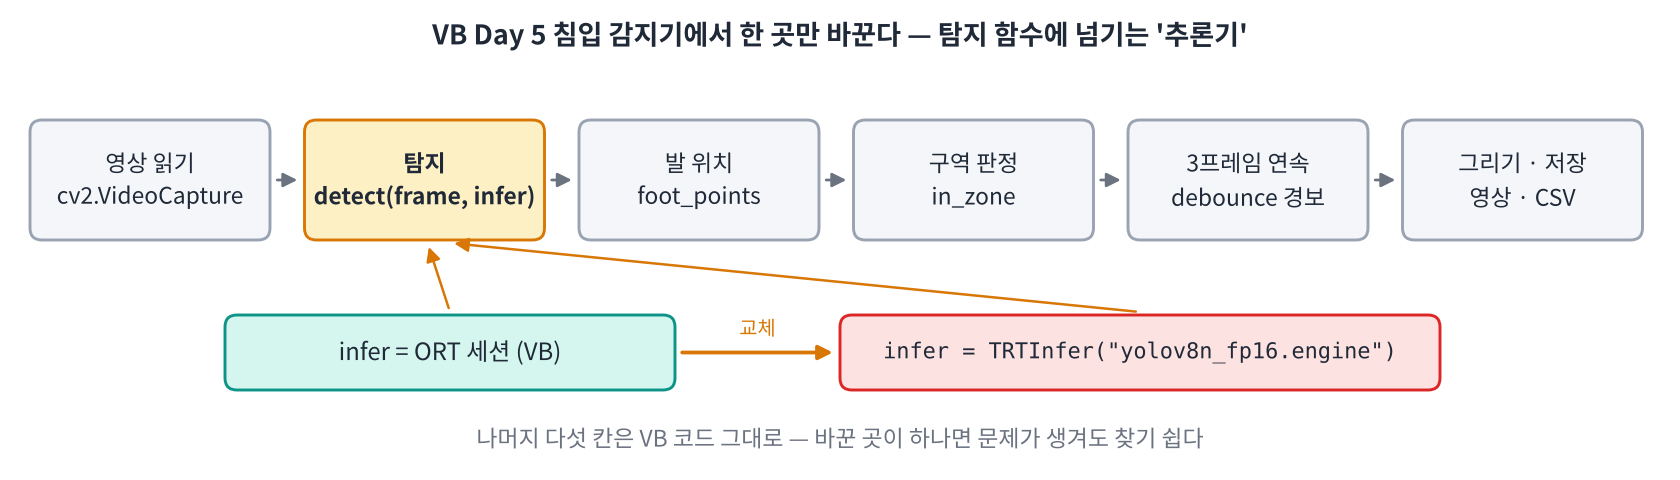

In [ ]:
#@title 🖼 그림 — 한 곳만 바꾼다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f5_swap.png", embed=True, width=900))

### 과제 1 — `process_frame` (20점)

프레임 한 장과 직전까지의 연속 프레임 수 `streak` 를 받아 ① 탐지 ② 발 위치 ③ 구역 안 여부 ④ debounce (구역 안에 누군가 있으면 `streak + 1`, 없으면 0 → `streak >= n_consec` 이면 경보) ⑤ 그리기를 하고, `(그린 프레임, 정보 딕셔너리, 새 streak)` 를 돌려주세요.

In [ ]:
def process_frame(frame, infer, streak, poly=GRASS, n_consec=3, conf=0.25, fps=None):
    boxes, scores = detect(frame, infer, conf=conf)
    feet = foot_points(boxes)
    inside = np.array([in_zone(p, poly) for p in feet], bool)
    streak = streak + 1 if inside.any() else ____
    alarm = int(streak >= ____)
    vis = draw_result(frame, boxes, inside, alarm, poly, fps)
    info = {"n_people": len(boxes), "n_inside": int(inside.sum()), "alarm": alarm}
    return vis, info, streak

vis, info, st = process_frame(frame530, yolo16, streak=2)
print(info, "| streak →", st)
show([vis], ["process_frame(frame530, TensorRT FP16, streak=2)"], cols=1, size=7)

In [ ]:
#@title 🔒 정답 보기 과제 1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSDqs7zsoJwgMSDilIDilIAKZGVmIHByb2Nlc3NfZnJhbWUoZnJhbWUsIGluZmVyLCBzdHJl"
    "YWssIHBvbHk9R1JBU1MsIG5fY29uc2VjPTMsIGNvbmY9MC4yNSwgZnBzPU5vbmUpOgogICAgYm94ZXMsIHNjb3Jl"
    "cyA9IGRldGVjdChmcmFtZSwgaW5mZXIsIGNvbmY9Y29uZikKICAgIGZlZXQgPSBmb290X3BvaW50cyhib3hlcykK"
    "ICAgIGluc2lkZSA9IG5wLmFycmF5KFtpbl96b25lKHAsIHBvbHkpIGZvciBwIGluIGZlZXRdLCBib29sKQogICAg"
    "c3RyZWFrID0gc3RyZWFrICsgMSBpZiBpbnNpZGUuYW55KCkgZWxzZSAwCiAgICBhbGFybSA9IGludChzdHJlYWsg"
    "Pj0gbl9jb25zZWMpCiAgICB2aXMgPSBkcmF3X3Jlc3VsdChmcmFtZSwgYm94ZXMsIGluc2lkZSwgYWxhcm0sIHBv"
    "bHksIGZwcykKICAgIGluZm8gPSB7Im5fcGVvcGxlIjogbGVuKGJveGVzKSwgIm5faW5zaWRlIjogaW50KGluc2lk"
    "ZS5zdW0oKSksICJhbGFybSI6IGFsYXJtfQogICAgcmV0dXJuIHZpcywgaW5mbywgc3RyZWFrCgp2aXMsIGluZm8s"
    "IHN0ID0gcHJvY2Vzc19mcmFtZShmcmFtZTUzMCwgeW9sbzE2LCBzdHJlYWs9MikKcHJpbnQoaW5mbywgInwgc3Ry"
    "ZWFrIOKGkiIsIHN0KQpzaG93KFt2aXNdLCBbInByb2Nlc3NfZnJhbWUoZnJhbWU1MzAsIFRlbnNvclJUIEZQMTYs"
    "IHN0cmVhaz0yKSJdLCBjb2xzPTEsIHNpemU9NykKCvCfkqEg7ZW07ISkCmZyYW1lNTMwIOydgCDqtazsl60g7JWI"
    "7JeQIOyCrOuejOydtCDsnojripQg7J6l66m0IOKAlCBzdHJlYWs9MiDroZwg67aI66CA7Jy866+A66GcIHN0cmVh"
    "ayAzIOKGkiDqsr3rs7QuIO2VnOuRkCDtlITroIjsnoQg7YqA64qUIOyYpO2DkOydhCDrp4nripQgVkIgRGF5IDUg"
    "7J2YIGRlYm91bmNlIOq3uOuMgOuhnOyeheuLiOuLpC4="
).decode("utf-8"))

### 과제 2 — `run_intrusion` (20점)

영상을 처음부터 끝까지 읽으며 `process_frame` 을 부르고, 결과 영상 (`out_path`) 과 프레임 로그 CSV (`out_path` 이름 + `_log.csv`) 를 저장하세요. 화면 오른쪽 위에는 **최근 30 프레임 평균 FPS** 를 그립니다. `max_frames` 를 주면 그 프레임까지만 (6교시 ORT 비교용). TensorRT FP16 으로 영상 전체를 처리합니다.

In [ ]:
def run_intrusion(source, out_path, infer, poly=GRASS, n_consec=3, conf=0.25, max_frames=None):
    cap = cv2.VideoCapture(source)                         # 영상을 여는 곳은 여기 한 곳 (나중에 카메라로)
    fps_v = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps_v, (W, H))
    log, ms, streak, i = [], [], 0, 0
    while max_frames is None or i < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        cur_fps = 1000 / np.mean(ms[-30:]) if ms else None
        vis, info, streak = process_frame(frame, ____, streak, poly, n_consec, conf, cur_fps)
        writer.write(vis)
        ms.append((time.perf_counter() - t0) * 1000)
        log.append({"frame": i, "time_s": round(i / fps_v, 1), **info, "ms": round(ms[-1], 2)})
        i += 1
    cap.release(); writer.release()
    with open(out_path.rsplit(".", 1)[0] + "_log.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(log[0])); w.writeheader(); w.writerows(____)
    return log

t_start = time.perf_counter()
log_trt = run_intrusion(VIDEO, "intrusion_trt.mp4", yolo16)
wall_trt = (time.perf_counter() - t_start) / len(log_trt) * 1000          # 읽기 · 저장까지 포함한 프레임당 시간
alarm = np.array([l["alarm"] for l in log_trt]); n_inside = np.array([l["n_inside"] for l in log_trt])
print(f"{len(log_trt)} 프레임 | 경보 {alarm.sum()} 프레임 | 처리 {np.mean([l['ms'] for l in log_trt]):.1f} ms · 전체 {wall_trt:.1f} ms / 프레임")

In [ ]:
#@title 🔒 정답 보기 과제 2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSDqs7zsoJwgMiDilIDilIAKZGVmIHJ1bl9pbnRydXNpb24oc291cmNlLCBvdXRfcGF0aCwg"
    "aW5mZXIsIHBvbHk9R1JBU1MsIG5fY29uc2VjPTMsIGNvbmY9MC4yNSwgbWF4X2ZyYW1lcz1Ob25lKToKICAgIGNh"
    "cCA9IGN2Mi5WaWRlb0NhcHR1cmUoc291cmNlKSAgICAgICAgICAgICAgICAgICAgICAgICAjIOyYgeyDgeydhCDs"
    "l6zripQg6rOz7J2AIOyXrOq4sCDtlZwg6rOzICjrgpjspJHsl5Ag7Lm066mU652866GcKQogICAgZnBzX3YgPSBj"
    "YXAuZ2V0KGN2Mi5DQVBfUFJPUF9GUFMpCiAgICBXLCBIID0gaW50KGNhcC5nZXQoY3YyLkNBUF9QUk9QX0ZSQU1F"
    "X1dJRFRIKSksIGludChjYXAuZ2V0KGN2Mi5DQVBfUFJPUF9GUkFNRV9IRUlHSFQpKQogICAgd3JpdGVyID0gY3Yy"
    "LlZpZGVvV3JpdGVyKG91dF9wYXRoLCBjdjIuVmlkZW9Xcml0ZXJfZm91cmNjKCoibXA0diIpLCBmcHNfdiwgKFcs"
    "IEgpKQogICAgbG9nLCBtcywgc3RyZWFrLCBpID0gW10sIFtdLCAwLCAwCiAgICB3aGlsZSBtYXhfZnJhbWVzIGlz"
    "IE5vbmUgb3IgaSA8IG1heF9mcmFtZXM6CiAgICAgICAgb2ssIGZyYW1lID0gY2FwLnJlYWQoKQogICAgICAgIGlm"
    "IG5vdCBvazoKICAgICAgICAgICAgYnJlYWsKICAgICAgICB0MCA9IHRpbWUucGVyZl9jb3VudGVyKCkKICAgICAg"
    "ICBjdXJfZnBzID0gMTAwMCAvIG5wLm1lYW4obXNbLTMwOl0pIGlmIG1zIGVsc2UgTm9uZQogICAgICAgIHZpcywg"
    "aW5mbywgc3RyZWFrID0gcHJvY2Vzc19mcmFtZShmcmFtZSwgaW5mZXIsIHN0cmVhaywgcG9seSwgbl9jb25zZWMs"
    "IGNvbmYsIGN1cl9mcHMpCiAgICAgICAgd3JpdGVyLndyaXRlKHZpcykKICAgICAgICBtcy5hcHBlbmQoKHRpbWUu"
    "cGVyZl9jb3VudGVyKCkgLSB0MCkgKiAxMDAwKQogICAgICAgIGxvZy5hcHBlbmQoeyJmcmFtZSI6IGksICJ0aW1l"
    "X3MiOiByb3VuZChpIC8gZnBzX3YsIDEpLCAqKmluZm8sICJtcyI6IHJvdW5kKG1zWy0xXSwgMil9KQogICAgICAg"
    "IGkgKz0gMQogICAgY2FwLnJlbGVhc2UoKTsgd3JpdGVyLnJlbGVhc2UoKQogICAgd2l0aCBvcGVuKG91dF9wYXRo"
    "LnJzcGxpdCgiLiIsIDEpWzBdICsgIl9sb2cuY3N2IiwgInciLCBuZXdsaW5lPSIiKSBhcyBmOgogICAgICAgIHcg"
    "PSBjc3YuRGljdFdyaXRlcihmLCBmaWVsZG5hbWVzPWxpc3QobG9nWzBdKSk7IHcud3JpdGVoZWFkZXIoKTsgdy53"
    "cml0ZXJvd3MobG9nKQogICAgcmV0dXJuIGxvZwoKdF9zdGFydCA9IHRpbWUucGVyZl9jb3VudGVyKCkKbG9nX3Ry"
    "dCA9IHJ1bl9pbnRydXNpb24oVklERU8sICJpbnRydXNpb25fdHJ0Lm1wNCIsIHlvbG8xNikKd2FsbF90cnQgPSAo"
    "dGltZS5wZXJmX2NvdW50ZXIoKSAtIHRfc3RhcnQpIC8gbGVuKGxvZ190cnQpICogMTAwMCAgICAgICAgICAjIOyd"
    "veq4sCDCtyDsoIDsnqXquYzsp4Ag7Y+s7ZWo7ZWcIO2UhOugiOyehOuLuSDsi5zqsIQKYWxhcm0gPSBucC5hcnJh"
    "eShbbFsiYWxhcm0iXSBmb3IgbCBpbiBsb2dfdHJ0XSk7IG5faW5zaWRlID0gbnAuYXJyYXkoW2xbIm5faW5zaWRl"
    "Il0gZm9yIGwgaW4gbG9nX3RydF0pCnByaW50KGYie2xlbihsb2dfdHJ0KX0g7ZSE66CI7J6EIHwg6rK967O0IHth"
    "bGFybS5zdW0oKX0g7ZSE66CI7J6EIHwg7LKY66asIHtucC5tZWFuKFtsWydtcyddIGZvciBsIGluIGxvZ190cnRd"
    "KTouMWZ9IG1zIMK3IOyghOyytCB7d2FsbF90cnQ6LjFmfSBtcyAvIO2UhOugiOyehCIpCgrwn5KhIO2VtOyEpAon"
    "7JiB7IOB7J2EIOyXrOuKlCDqs7PsnYAg7ZWcIOqzsycg4oCUIHNvdXJjZSDsl5Ag7YyM7J28IOydtOumhCDrjIDs"
    "i6Ag7Lm066mU6528IOuyiO2YuCAoMCkg64KYIFJUU1Ag7KO87IaM66W8IOyjvOuptCDqt7jrjIDroZwg7Iuk7Iuc"
    "6rCEIOqwkOyngOq4sOqwgCDrkKnri4jri6QgKDExLzI1fiDtmITsnqUg7JWI7KCEIO2UhOuhnOygne2KuCku"
).decode("utf-8"))

#### 📌 5교시 정리

- `process_frame` = 탐지 (infer) → 발 위치 → 구역 → debounce → 그리기. `run_intrusion` = 영상 루프 + 저장.
- 바뀐 것은 `infer` 하나 — `yolo16` (TRTInfer) 을 넘겼을 뿐 나머지는 VB 그대로.

## 6교시 — 미니 프로젝트 ② 결과 만들기: 영상 · 이벤트 · 성능표

> 🎬 **애니메이션** [D5-6 결과물 네 가지](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

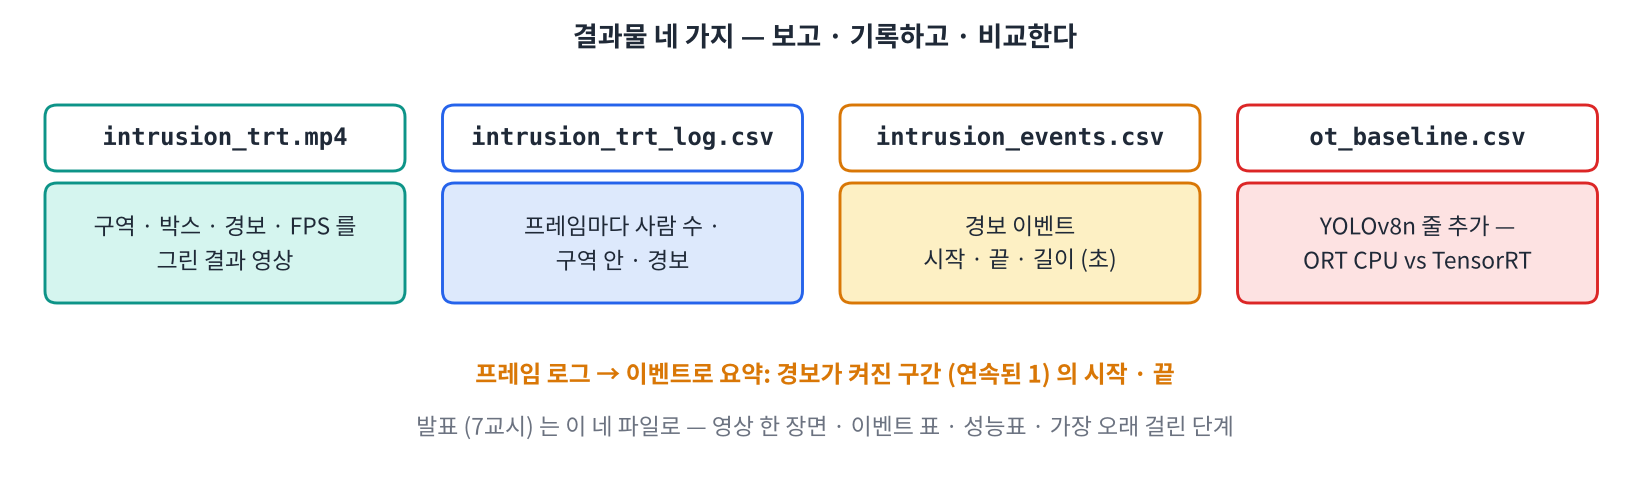

In [ ]:
#@title 🖼 그림 — 결과물 네 가지
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f6_outputs.png", embed=True, width=880))

In [ ]:
def to_h264(src, dst):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-c:v", "libx264", "-preset", "veryfast", "-crf", "28", "-pix_fmt", "yuv420p", dst], check=True)
    return dst

def play(path, width=640):
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    return HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>')

to_h264("intrusion_trt.mp4", "intrusion_trt_h264.mp4")
plt.figure(figsize=(9, 2.6)); tt = np.arange(len(log_trt)) / V_FPS
plt.plot(tt, n_inside, label="people in zone"); plt.fill_between(tt, 0, alarm * max(n_inside.max(), 1), color="red", alpha=0.25, label="ALARM")
plt.xlabel("time (s)"); plt.legend(); plt.tight_layout(); plt.show()
display(play("intrusion_trt_h264.mp4"))

### 과제 3 — 이벤트 요약 (20점)

프레임마다의 `alarm` (0/1) 을 **이벤트** (경보가 연속으로 켜진 구간) 로 요약하는 `find_events(alarm, fps)` 를 완성하고 (VB Day 5 와 같음), 이벤트마다 `start_s` · `end_s` · `duration_s` 를 `intrusion_events.csv` 로 저장하세요. 끝 프레임은 경보가 켜져 있던 **마지막** 프레임입니다.

In [ ]:
def find_events(alarm, fps):
    events, start = [], None
    for i, a in enumerate(alarm):
        if a and start is None:
            start = i
        elif not a and start is not None:
            events.append((start / fps, (____) / fps)); start = None
    if start is not None:
        events.append((start / fps, (len(alarm) - 1) / fps))
    return events

events = find_events(alarm, V_FPS)
with open("intrusion_events.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["event", "start_s", "end_s", "duration_s"])
    for k, (a, b) in enumerate(events):
        w.writerow([k + 1, round(a, 1), round(b, 1), round(b - a + 1 / V_FPS, 1)])
display(pd.read_csv("intrusion_events.csv"))

In [ ]:
#@title 🔒 정답 보기 과제 3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSDqs7zsoJwgMyDilIDilIAKZGVmIGZpbmRfZXZlbnRzKGFsYXJtLCBmcHMpOgogICAgZXZl"
    "bnRzLCBzdGFydCA9IFtdLCBOb25lCiAgICBmb3IgaSwgYSBpbiBlbnVtZXJhdGUoYWxhcm0pOgogICAgICAgIGlm"
    "IGEgYW5kIHN0YXJ0IGlzIE5vbmU6CiAgICAgICAgICAgIHN0YXJ0ID0gaQogICAgICAgIGVsaWYgbm90IGEgYW5k"
    "IHN0YXJ0IGlzIG5vdCBOb25lOgogICAgICAgICAgICBldmVudHMuYXBwZW5kKChzdGFydCAvIGZwcywgKGkgLSAx"
    "KSAvIGZwcykpOyBzdGFydCA9IE5vbmUKICAgIGlmIHN0YXJ0IGlzIG5vdCBOb25lOgogICAgICAgIGV2ZW50cy5h"
    "cHBlbmQoKHN0YXJ0IC8gZnBzLCAobGVuKGFsYXJtKSAtIDEpIC8gZnBzKSkKICAgIHJldHVybiBldmVudHMKCmV2"
    "ZW50cyA9IGZpbmRfZXZlbnRzKGFsYXJtLCBWX0ZQUykKd2l0aCBvcGVuKCJpbnRydXNpb25fZXZlbnRzLmNzdiIs"
    "ICJ3IiwgbmV3bGluZT0iIikgYXMgZjoKICAgIHcgPSBjc3Yud3JpdGVyKGYpOyB3LndyaXRlcm93KFsiZXZlbnQi"
    "LCAic3RhcnRfcyIsICJlbmRfcyIsICJkdXJhdGlvbl9zIl0pCiAgICBmb3IgaywgKGEsIGIpIGluIGVudW1lcmF0"
    "ZShldmVudHMpOgogICAgICAgIHcud3JpdGVyb3coW2sgKyAxLCByb3VuZChhLCAxKSwgcm91bmQoYiwgMSksIHJv"
    "dW5kKGIgLSBhICsgMSAvIFZfRlBTLCAxKV0pCmRpc3BsYXkocGQucmVhZF9jc3YoImludHJ1c2lvbl9ldmVudHMu"
    "Y3N2IikpCgrwn5KhIO2VtOyEpArqsr3rs7TqsIAg6rq87KeEIO2UhOugiOyehOydtCBpIOydtOuptCDsvJzsoLgg"
    "7J6I642YIOuniOyngOuniSDtlITroIjsnoTsnYAgaSDiiJIgMS4gZHVyYXRpb24g7JeQIDEvZnBzIOulvCDrjZTt"
    "lZjripQg6rKD7J2AICftlITroIjsnoQg7ZWY64KY64+EIOyLnOqwhOydtCDsnojri6QnIOuKlCDrnLsgKO2VnCDt"
    "lITroIjsnoTsp5zrpqwg7J2067Kk7Yq4ID0gMC4xIOy0iCku"
).decode("utf-8"))

### 과제 4 — 성능 비교 · 최종 성능표 (20점)

① **추론만** — ORT CPU · TensorRT FP32 · TensorRT FP16 을 `bench_fn` 으로 (letterbox 된 입력 한 장). ② **파이프라인 전체** — ORT CPU 로 `run_intrusion` 을 처음 200 프레임만 돌려 TensorRT FP16 (과제 2) 과 프레임당 시간을 비교합니다. 다섯 줄을 `ot_baseline.csv` 에 이어 붙이세요 (Day 4 파일이 있으면 그 아래에).

In [ ]:
lb, _, _ = letterbox(frame200)
x640 = (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32)
rows = []
for name, f, prec in [("ORT CPU", ort_infer, "FP32"), ("TRT FP32", yolo32, "FP32"), ("TRT FP16", yolo16, "FP16")]:
    r = bench_fn(lambda: f(x640), n=30 if name == "ORT CPU" else 100, warm=5)
    rows.append({"model": "yolov8n (추론만)", "provider": name, "precision": prec, "threads": 0, "level": "ALL", "batch": 1, **r})

t_start = time.perf_counter()
log_ort = run_intrusion(VIDEO, "intrusion_ort200.mp4", ort_infer, max_frames=200)
wall_ort = (time.perf_counter() - t_start) / len(log_ort) * 1000
for name, prec, w_ms, lg in [("ORT CPU", "FP32", wall_ort, log_ort), ("TRT FP16", "FP16", wall_trt, log_trt)]:
    p_ms = np.array([l["ms"] for l in lg])
    rows.append({"model": "intrusion pipeline", "provider": name, "precision": prec, "threads": 0, "level": "ALL", "batch": 1,
                 "mean": w_ms, "p50": np.percentile(p_ms, 50), "p95": np.percentile(p_ms, 95), "fps": 1000 / ____})
final = pd.DataFrame(rows)
old = pd.read_csv("ot_baseline.csv") if os.path.exists("ot_baseline.csv") else pd.DataFrame()
if len(old) and "precision" not in old.columns:
    old["precision"] = "FP32"
pd.concat([old, final], ignore_index=True).to_csv("ot_baseline.csv", index=False)
display(final[["model", "provider", "precision", "mean", "p95", "fps"]])
print(f"파이프라인: ORT CPU {1000 / wall_ort:.1f} FPS → TensorRT FP16 {1000 / wall_trt:.1f} FPS ({wall_ort / wall_trt:.1f}배) · 영상 원래 속도 {V_FPS:.0f} FPS")

In [ ]:
#@title 🔒 정답 보기 과제 4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSDqs7zsoJwgNCDilIDilIAKbGIsIF8sIF8gPSBsZXR0ZXJib3goZnJhbWUyMDApCng2NDAg"
    "PSAobGJbLi4uLCA6Oi0xXS50cmFuc3Bvc2UoMiwgMCwgMSlbTm9uZV0gLyAyNTUuMCkuYXN0eXBlKG5wLmZsb2F0"
    "MzIpCnJvd3MgPSBbXQpmb3IgbmFtZSwgZiwgcHJlYyBpbiBbKCJPUlQgQ1BVIiwgb3J0X2luZmVyLCAiRlAzMiIp"
    "LCAoIlRSVCBGUDMyIiwgeW9sbzMyLCAiRlAzMiIpLCAoIlRSVCBGUDE2IiwgeW9sbzE2LCAiRlAxNiIpXToKICAg"
    "IHIgPSBiZW5jaF9mbihsYW1iZGE6IGYoeDY0MCksIG49MzAgaWYgbmFtZSA9PSAiT1JUIENQVSIgZWxzZSAxMDAs"
    "IHdhcm09NSkKICAgIHJvd3MuYXBwZW5kKHsibW9kZWwiOiAieW9sb3Y4biAo7LaU66Gg66eMKSIsICJwcm92aWRl"
    "ciI6IG5hbWUsICJwcmVjaXNpb24iOiBwcmVjLCAidGhyZWFkcyI6IDAsICJsZXZlbCI6ICJBTEwiLCAiYmF0Y2gi"
    "OiAxLCAqKnJ9KQoKdF9zdGFydCA9IHRpbWUucGVyZl9jb3VudGVyKCkKbG9nX29ydCA9IHJ1bl9pbnRydXNpb24o"
    "VklERU8sICJpbnRydXNpb25fb3J0MjAwLm1wNCIsIG9ydF9pbmZlciwgbWF4X2ZyYW1lcz0yMDApCndhbGxfb3J0"
    "ID0gKHRpbWUucGVyZl9jb3VudGVyKCkgLSB0X3N0YXJ0KSAvIGxlbihsb2dfb3J0KSAqIDEwMDAKZm9yIG5hbWUs"
    "IHByZWMsIHdfbXMsIGxnIGluIFsoIk9SVCBDUFUiLCAiRlAzMiIsIHdhbGxfb3J0LCBsb2dfb3J0KSwgKCJUUlQg"
    "RlAxNiIsICJGUDE2Iiwgd2FsbF90cnQsIGxvZ190cnQpXToKICAgIHBfbXMgPSBucC5hcnJheShbbFsibXMiXSBm"
    "b3IgbCBpbiBsZ10pCiAgICByb3dzLmFwcGVuZCh7Im1vZGVsIjogImludHJ1c2lvbiBwaXBlbGluZSIsICJwcm92"
    "aWRlciI6IG5hbWUsICJwcmVjaXNpb24iOiBwcmVjLCAidGhyZWFkcyI6IDAsICJsZXZlbCI6ICJBTEwiLCAiYmF0"
    "Y2giOiAxLAogICAgICAgICAgICAgICAgICJtZWFuIjogd19tcywgInA1MCI6IG5wLnBlcmNlbnRpbGUocF9tcywg"
    "NTApLCAicDk1IjogbnAucGVyY2VudGlsZShwX21zLCA5NSksICJmcHMiOiAxMDAwIC8gd19tc30pCmZpbmFsID0g"
    "cGQuRGF0YUZyYW1lKHJvd3MpCm9sZCA9IHBkLnJlYWRfY3N2KCJvdF9iYXNlbGluZS5jc3YiKSBpZiBvcy5wYXRo"
    "LmV4aXN0cygib3RfYmFzZWxpbmUuY3N2IikgZWxzZSBwZC5EYXRhRnJhbWUoKQppZiBsZW4ob2xkKSBhbmQgInBy"
    "ZWNpc2lvbiIgbm90IGluIG9sZC5jb2x1bW5zOgogICAgb2xkWyJwcmVjaXNpb24iXSA9ICJGUDMyIgpwZC5jb25j"
    "YXQoW29sZCwgZmluYWxdLCBpZ25vcmVfaW5kZXg9VHJ1ZSkudG9fY3N2KCJvdF9iYXNlbGluZS5jc3YiLCBpbmRl"
    "eD1GYWxzZSkKZGlzcGxheShmaW5hbFtbIm1vZGVsIiwgInByb3ZpZGVyIiwgInByZWNpc2lvbiIsICJtZWFuIiwg"
    "InA5NSIsICJmcHMiXV0pCnByaW50KGYi7YyM7J207ZSE65287J24OiBPUlQgQ1BVIHsxMDAwIC8gd2FsbF9vcnQ6"
    "LjFmfSBGUFMg4oaSIFRlbnNvclJUIEZQMTYgezEwMDAgLyB3YWxsX3RydDouMWZ9IEZQUyAoe3dhbGxfb3J0IC8g"
    "d2FsbF90cnQ6LjFmfeuwsCkgwrcg7JiB7IOBIOybkOuemCDsho3rj4Qge1ZfRlBTOi4wZn0gRlBTIikKCvCfkqEg"
    "7ZW07ISkCuy2lOuhoOunjOydmCDrsLDsiJjrs7Tri6Qg7YyM7J207ZSE65287J247J2YIOuwsOyImOqwgCDsnpHr"
    "i6Qg4oCUIDTqtZDsi5zsl5DshJwg67O4ICfri6TsnYwg67OR66qpJyDrlYzrrLjsnoXri4jri6QuIO2MjOydtO2U"
    "hOudvOyduCBGUFMg6rCAIOyYgeyDgSBGUFMgKDEwKSDrs7Tri6Qg7YGs66m0IOyLpOyLnOqwhOycvOuhnCDrlLDr"
    "nbzqsIgg7IiYIOyeiOyKteuLiOuLpC4K7J20IOyFgOydhCDrkZAg67KIIOyLpO2Wie2VmOuptCDspITsnbQg65GQ"
    "IOuyiCDrtpnsirXri4jri6Qg4oCUIERheSA0IO2MjOydvOydhCDri6Tsi5wg7Jis66as6rOgIOyLpO2Wie2VmOyE"
    "uOyalC4="
).decode("utf-8"))

### 채점 셀 (과제 1~4 · 80점)

In [ ]:
score = 0
try:
    for fr_ in [frame200, frame530]:
        b_, _ = detect(fr_, yolo16)
        ins_ = np.array([in_zone(p) for p in foot_points(b_)], bool)
        _, i2, s2 = process_frame(fr_, yolo16, streak=2)
        _, i0, s0 = process_frame(fr_, yolo16, streak=0)
        assert i2["n_people"] == len(b_) and i2["n_inside"] == int(ins_.sum())
        assert s2 == (3 if ins_.any() else 0) and i2["alarm"] == int(ins_.any()) and i0["alarm"] == 0 and s0 == int(ins_.any())
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    rows_ = list(csv.DictReader(open("intrusion_trt_log.csv")))
    assert len(log_trt) == V_N == len(rows_) and os.path.getsize("intrusion_trt.mp4") > 100_000
    s_, ok_ = 0, True
    for l in log_trt:
        s_ = s_ + 1 if l["n_inside"] > 0 else 0
        ok_ &= (l["alarm"] == int(s_ >= 3))
    assert ok_ and alarm.sum() > 0
    score += 20; print("✅ 과제 2  +20", f"(경보 {alarm.sum()} 프레임)")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    rising = int(((alarm[1:] == 1) & (alarm[:-1] == 0)).sum() + (alarm[0] == 1))
    assert len(events) == rising and all(a <= b for a, b in events)
    assert find_events([0, 1, 1, 0, 1], 10) == [(0.1, 0.2), (0.4, 0.4)]
    ev = pd.read_csv("intrusion_events.csv")
    assert len(ev) == len(events) and list(ev.columns) == ["event", "start_s", "end_s", "duration_s"] and (ev.duration_s > 0).all()
    score += 20; print("✅ 과제 3  +20", f"(이벤트 {len(events)}번)")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    t4 = pd.read_csv("ot_baseline.csv")
    last = t4.tail(5)
    assert last.provider.tolist() == ["ORT CPU", "TRT FP32", "TRT FP16", "ORT CPU", "TRT FP16"]
    assert np.allclose(last.fps * last["mean"], 1000) and len(log_ort) == 200
    assert abs(last["mean"].iloc[-1] - wall_trt) < 1e-6 and abs(last["mean"].iloc[-2] - wall_ort) < 1e-6
    score += 20; print("✅ 과제 4  +20", f"({len(t4)}줄)")
except Exception as e: print("❌ 과제 4", repr(e))
print(f"\n자동 채점 {score} / 80  (+ 과제 5 발표 · 해석 강사 채점 20점, 7교시)")

#### 📌 6교시 정리

- 프레임 로그 → `find_events` → 이벤트 CSV. 경보가 '몇 번 · 언제 · 얼마나'.
- 추론만 vs 파이프라인 전체 — 같은 성능표에 둘 다. 배수가 다른 이유 = 4교시의 다음 병목.

## 7교시 — 팀 발표 (과제 5 · 20점)

팀별 **3분**. 아래 세 장면으로 발표하고, 다른 팀 발표에 질문 하나씩.

> 🎬 **애니메이션** [D5-7 발표 3분 구성](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

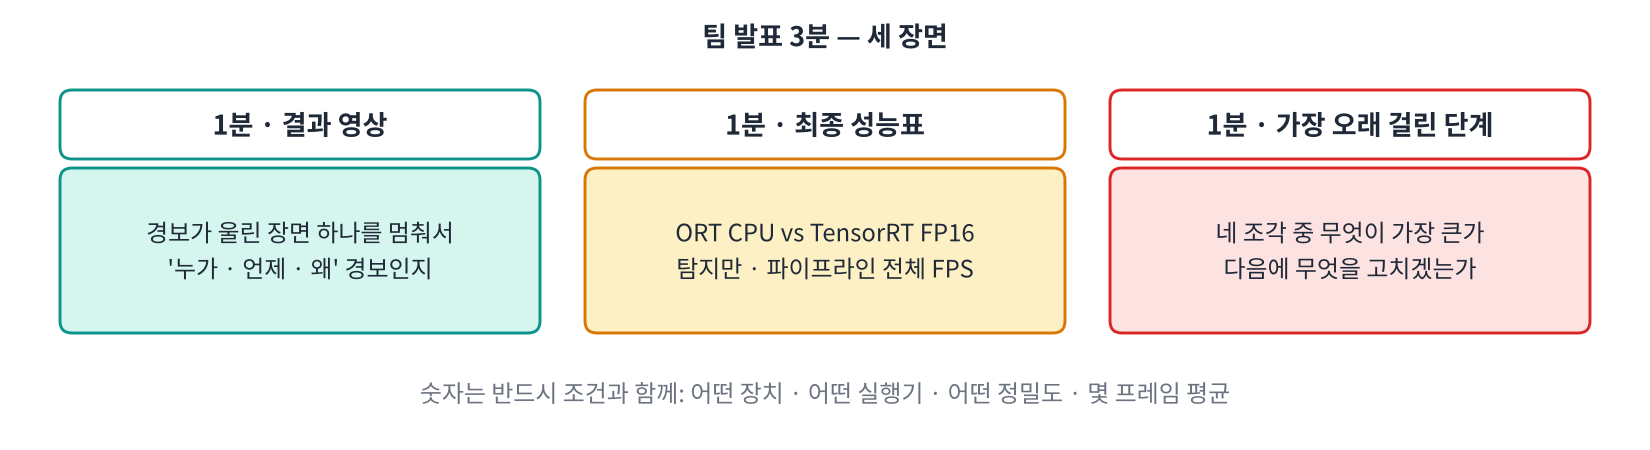

In [ ]:
#@title 🖼 그림 — 팀 발표 3분 — 세 장면
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f7_present.png", embed=True, width=880))

| 장면 | 보여 줄 것 | 노트북에서 |
|---|---|---|
| 1 · 결과 영상 (1분) | 경보가 울린 장면 하나 — 누가 · 언제 · 왜 경보인지 | 6교시 영상 · `intrusion_events.csv` |
| 2 · 최종 성능표 (1분) | ORT CPU vs TensorRT FP16 — 추론만 · 파이프라인 FPS, FP16 의 AP | 과제 4 표 · 3-1 표 |
| 3 · 가장 오래 걸린 단계 (1분) | 네 조각 중 가장 큰 것과 이유, 다음에 고칠 것 | 4-2 그래프 |

**채점 기준 (20점)** — 숫자를 조건과 함께 말했는가 (5) · FP16 정확도 판단 근거 (5) · 병목과 다음 개선안 (5) · 질문에 대한 답 (5).

✍️ *발표 메모 — 아래에 적어 두세요.*

1. 경보 장면:
2. 성능표 핵심 숫자 (조건 포함):
3. 가장 오래 걸린 단계 · 이유 · 다음 개선:

In [ ]:
#@title 🔒 해설 보기 7교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKKOyLpO2WiSDsmIggwrcg66qo67KUIOuLteyViCDtmJXtg5wpCjEuICdu7LSI"
    "7JeQIOyelOuUlCDqtazsl63snLzroZwg6rG47Ja0IOuTpOyWtOyYqCDrs7TtlonsnpDsnZgg67CcIOychOy5mOqw"
    "gCAz7ZSE66CI7J6EIOyXsOyGjSDqtazsl60g7JWIIOKGkiDqsr3rs7QuIOuwleyKpOqwgCDslYTri4jrnbwg67Cc"
    "IOychOy5mOuhnCDtjJDsoJXtlbTshJwg6rWs7JetIOyYhuydhCDsp4DrgpjripQg7IKs656M7J2AIOqyveuztOqw"
    "gCDsl4bri6QuJwoyLiAnQ29sYWIgVDQgwrcg67Cw7LmYIDEgwrcgNjQwIOyeheugpSDquLDspIA6IOy2lOuhoOun"
    "jOydgCBPUlQgQ1BVIOuMgOu5hCBUZW5zb3JSVCBGUDE2IOydtCDsiJjsi60g67CwLCDtjIzsnbTtlITrnbzsnbgg"
    "7KCE7LK064qUIOq3uOuztOuLpCDsnpHsnYAg67Cw7IiYLgogICBGUDE2IEFQNTAg7J2AIE9SVCDsmYAg7LCo7J20"
    "IDAuMHgg7J207ZWYIOKGkiDsoJXtmZXrj4Qg7IaQ7IukIOyXhuydtCDsgqzsmqkg6rCA64qlLicKMy4gJ1RlbnNv"
    "clJUIOuhnCDrsJTqvrwg65Kk7JeQ64qUIOy2lOuhoOuztOuLpCDtm4TsspjrpqwgKFB5dGhvbiBOTVMpIMK3IOq3"
    "uOumrOq4sOqwgCDrjZQg7YGs64ukLiDri6TsnYw6IHRvcmNodmlzaW9uLm9wcy5ubXMg66GcIEdQVSBOTVMsIOyg"
    "hOyymOumrOulvCBHUFUg66GcLic="
).decode("utf-8"))

## 8교시 — 5일 종합 퀴즈 · 제출 · 다음 과목

| 시간 | 할 일 |
|---|---|
| 17:00–17:25 | **5일 종합 필기 퀴즈 30문항** (Google Forms — 강사가 링크 공유) |
| 17:25–17:35 | 제출 파일 만들기 · 구글 폼 제출 |
| 17:35–17:50 | 5일 정리 · 다음 과목 연결 |

> 🎬 **애니메이션** [D5-8 5일 지도 · 다음 과목](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/animation.html#d5-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day5/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
# ▶ 제출 파일 — trt_이름.zip (이름을 바꾸세요). 노트북 (.ipynb) 은 '파일 → 다운로드' 로 받아 함께 제출
NAME = "홍길동"
files = ["ot_baseline.csv", "intrusion_events.csv", "intrusion_trt_log.csv", "intrusion_trt_h264.mp4"]
import zipfile
with zipfile.ZipFile(f"trt_{NAME}.zip", "w") as z:
    for f in files:
        if os.path.exists(f):
            z.write(f)
print(f"trt_{NAME}.zip", [(f, f"{os.path.getsize(f) / 1e6:.2f} MB") for f in files if os.path.exists(f)])

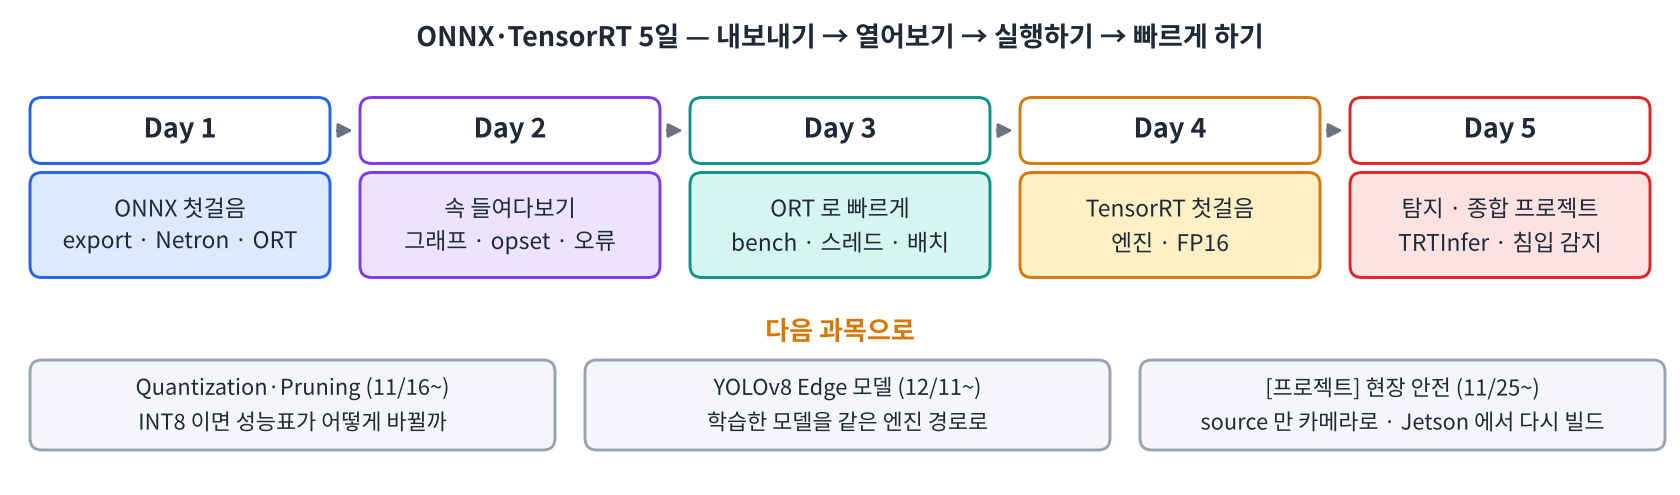

In [ ]:
#@title 🖼 그림 — ONNX·TensorRT 5일 지도
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day5/img/f8_map5.png", embed=True, width=900))

### 5일 정리

| 일차 | 계단 | 오늘까지 쌓인 도구 |
|---|---|---|
| Day 1 | ONNX 첫걸음 | `torch.onnx.export` · Netron · `InferenceSession` · `allclose` |
| Day 2 | ONNX 속 들여다보기 | `describe_onnx` · opset · `dynamic_axes` · `verify` · onnxslim |
| Day 3 | ONNX Runtime 으로 빠르게 | `bench` · 스레드 · 최적화 레벨 · CUDA EP · 배치 · profiling |
| Day 4 | TensorRT 첫걸음 | polygraphy · `build_engine` · `trt_runner` · FP16 · 엔진 인스펙터 |
| Day 5 | 탐지 · 종합 프로젝트 | `TRTInfer` · `detect(frame, infer)` · AP 비교 · 네 조각 시간 · 침입 감지 |

### 셀프 체크

- [ ] 함수를 클래스로 묶어 엔진 준비 (한 번) 와 실행 (여러 번) 을 나눌 수 있다
- [ ] YOLOv8n 엔진의 입출력 (1, 3, 640, 640) → (1, 84, 8400) 을 설명할 수 있다
- [ ] 추론기를 인자로 받는 `detect` 로 ORT · TensorRT 를 바꿔 끼울 수 있다
- [ ] 같은 데이터 · 같은 함수로 FP32 와 FP16 의 AP 를 비교할 수 있다
- [ ] 한 프레임을 네 조각으로 재고 다음 병목을 찾을 수 있다
- [ ] 침입 감지 파이프라인에서 추론기만 바꿔 결과 영상 · 이벤트 · 성능표를 만들 수 있다

### 다음 과목으로

- **Quantization·Pruning (11/16~)** — INT8 이면 오늘 성능표가 어떻게 바뀔까? `ot_baseline.csv` 가 비교 기준.
- **[프로젝트] 현장 안전 모니터링 (11/25~)** — `run_intrusion` 의 `source` 만 카메라로. Jetson 에서는 `.onnx` 를 가져가 **그 장치에서 다시 빌드**.
- **YOLOv8 Edge 모델 (12/11~)** — 직접 학습한 YOLO 를 같은 경로 (ONNX → 엔진 → TRTInfer) 로.

**5일 동안 수고 많으셨습니다.** 노트북 · `ot_baseline.csv` · 엔진을 만든 `.onnx` 를 Drive 에 저장해 두세요.